# 5주차 · 우주발사체의 유도 · 항법 · 제어
## Navigation, Guidance and Control of Space Launch Vehicles

**우주수송정책과 발사체 기술** · 대학원 강의노트 (실습형 Jupyter Notebook)

---

- 로켓방정식 = **가능성**, 유도·항법·제어(GNC) = 가능성을 **실제 궤도**로 전환하는 수단
- 본 노트북 = 양자 간 간극을 이론·수식·수치실습으로 연결

| 부(部) | 핵심 질문 | 주요 실습 |
|---|---|---|
| **제0부** 서론 | 왜 로켓 이론과 함께 GNC를 보는가 | ΔV 손실항 분해 |
| **제1부** 개관 | 항법·유도·제어는 무엇을 나누어 맡는가 | GNC 블록선도 작도 |
| **제2부** 항법 | 발사체는 자기 위치를 어떻게 아는가 | 스트랩다운 적분, 오차 성장, 정렬, 칼만필터 |
| **제2부 심화** 관성센서 | 센서 안에서는 무슨 일이 일어나는가 | 서보 가속도계, DTG, RLG 록인, FOG 위상변조, HRG, MEMS, 코닝, 슐러, 이중화 |
| **제3부** 유도 | 어디로 가야 하는지 누가 정하는가 | 오차 예산, 바람 하중, **최적 조향법칙 수치해** |
| **제4부** 사례 | 실제 발사체는 어떤 선택을 했는가 | 누리호 2차 비행시험 결과 해석 |

> **사용법**
> - `Run All`로 전체 1회 실행 후, 각 절의 `연습` 셀에서 파라미터 변경 → 결과 변화 관찰
> - 모든 수치 결과는 셀 실행으로 재현 (하드코딩된 그림 없음)
> - 코드 셀 = **한 줄 함수 호출**만 표시, 세부 코드는 공용 모듈 `course_interactive.py`에 분리
> - `widget_…()` 셀 = 실행 시 **슬라이더** 생성 → 파라미터 변경에 따른 그래프 변화 관찰
> - 실물 사진 = 온라인 상태에서 표시 (Wikimedia Commons)

---
## 제0부 · 환경 설정

- 아래 셀 1회 실행 → 공용 모듈 `course_interactive.py`를 GitHub(`lecture/_shared/`)에서 내려받아 로드
  - 5주차 그래프·표·위젯의 세부 코드 = 공용 모듈의 "5주차 위젯 함수" 블록에 위치 (강의 흐름에 집중하기 위한 분리)
  - 코드 확인: 내려받은 `course_interactive.py` 열람
- 이후 모든 셀이 본 셀에 의존

> **표기 방침**
> - 강의 서술(마크다운): **한글**
> - 코드 셀의 표·그림·출력 문구(제목·범례·축·캡션): **영어**
> - 사유: 한글 폰트가 없는 환경(Colab·서버·Windows/Mac 기본 설정 등)에서도 그림·표가 깨지지 않고 동일하게 표시
> - 함수 이름의 `ex2_4` 등 번호 = 본문 절 번호와 대응, `widget_…` = 슬라이더형 실습

In [ ]:
# ▶ 실행 전 준비 — 이 셀을 먼저 실행하세요 (약 10~20초 소요)
!pip install -q ipywidgets
!apt-get -qq install -y fonts-nanum > /dev/null 2>&1

import urllib.request
urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/gabraxas/LVs-and-Policy/main/lecture/_shared/course_interactive.py",
    "course_interactive.py")

from course_interactive import *
setup_korean_font()
print("준비 완료 — 아래 셀들을 순서대로 실행하며 강의를 진행하세요.")

---
# 서론 · 왜 「로켓 이론」과 함께 유도·항법·제어를 보는가

이상 로켓방정식이 답하지 못하는 세 가지 질문

### ① 방정식은 '가능성'만 제시
- Tsiolkovsky 식 = 추진제를 이상적으로 모두 소모했을 때 얻는 속도증분의 **상한**
- 그 속도를 *어느 방향으로* 쌓을지는 방정식 밖의 문제

### ② 손실항의 크기를 결정
- 실제 필요 ΔV = 중력손실 + 항력손실 + 조향손실
- **조향손실(steering loss)** = 전적으로 유도법칙이 만들어내는 항

### ③ 성능 산포를 흡수
- 추력·비추력·질량 = 3σ 수준의 산포 보유
- **폐루프 유도** = 산포를 실시간 흡수하여 목표궤도에 수렴시키는 유일한 장치

$$\Delta V_{ideal} = I_{sp}\,g_0 \ln\!\left(\frac{m_0}{m_f}\right)$$

$$\Delta V_{required} = \Delta V_{orbit} + \Delta V_{gravity} + \Delta V_{drag} + \Delta V_{steering}$$

> - 좌변(추진 성능)과 우변 첫 항(궤도역학) = 설계자의 선택
> - 뒤의 세 손실항 = 비행 중 **어떻게 조종하는가**에 의해 결정
> - → **유도·항법·제어는 로켓방정식의 나머지 절반**

| 관점 | 함의 |
|---|---|
| **설계** | 궤적·유도 설계 미확정 → 필요 ΔV 미확정 → 단 구성(staging)·이륙질량 미확정 |
| **정책** | 고성능 관성센서·유도 알고리즘 = 탄도미사일 기술과 물리적으로 동일 → GNC는 수출통제(MTCR)의 핵심 품목이자 국산화의 병목 |

== Typical dV budget for a LEO insertion mission (illustrative) ==
               Item  dV [m/s]                         Set by
   Orbital velocity      7800              Orbital mechanics
       Gravity loss      1200   Trajectory / guidance design
          Drag loss       150             Shape & trajectory
      Steering loss       100                   Guidance law
Earth rotation gain      -400 Launch site latitude & azimuth
TOTAL (required dV)      8850                              -

Required dV = 8,850 m/s  ->  mass ratio m0/mf = 20.25  (Isp = 300 s)
With zero losses                  m0/mf = 14.17
-> The 1,050 m/s of losses inflate the mass ratio by 1.43x.
-> Cutting steering loss by 100 m/s alone saves about 3,342 kg of propellant on a 100 t vehicle.


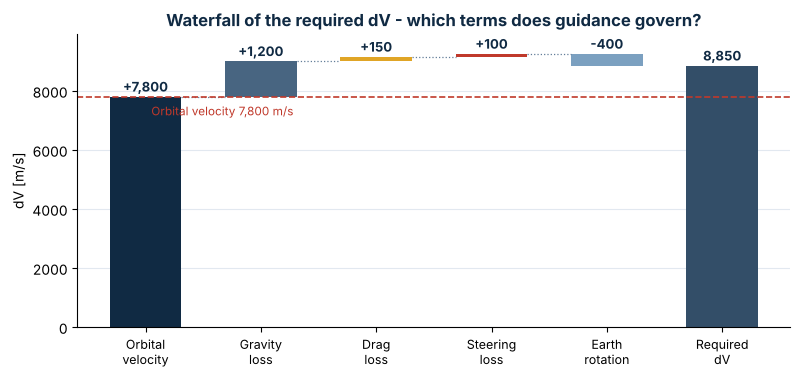

In [2]:
ex0_1_dv_waterfall()

---
## 학습목표

본 노트북 학습 후 **설명하고 계산할 수 있어야** 할 사항

1. **항법·유도·제어의 구분**
   - 세 기능이 각각 답하는 질문과 GNC 루프에서의 위치
   - 내루프/외루프의 대역폭 분리 원리
2. **관성센서 하드웨어의 물리 원리**
   - 서보 가속도계·DTG·RLG·FOG·HRG·MEMS 자이로의 측정 원리와 고유 오차(록인, 위상 감도, 모드 정합)
   - 실제 장치의 형상과 세대별 기술 변화
3. **관성항법의 원리와 오차 성장**
   - 자이로·가속도계의 측정량과 적분 구조
   - 센서 바이어스가 자세·속도·위치 오차로 $t,\ t^2,\ t^3$ 성장하는 과정의 정량화
4. **유도 법칙의 유래**
   - 최적제어 문제에서 이중선형 탄젠트 조향법칙이 도출되는 경로
   - 실제 발사체가 근사형을 사용하는 이유
5. **사례 기반 성능 해석**
   - 누리호 2차 비행시험 결과를 항법오차·유도오차·잔류추력 오차로 분해·해석
   - 국산화 과제 도출

> 본 자료 = 한국항공우주연구원 발사체 유도항법 강의자료(2024) 등 공개 문헌의 내용을 강의 목적에 맞게 재구성·재서술한 것 (상세 서지: 마지막 절)

---
# 제1부 · 유도·항법·제어 개관

> 대항해시대의 항해술에서 발사체 비행소프트웨어까지 — 세 기능은 왜 분리되었는가

## 1.1 세 개의 질문: 항법 · 유도 · 제어

- GNC = 단일 기능이 아니라 **성격이 다른 세 질문**에 대한 답의 결합

| 기능 | 질문 | 내용 |
|---|---|---|
| **항법 (Navigation)** | "나는 지금 어디에 있는가" | 각속도·비력(specific force) 측정값 → 현재 자세·속도·위치 벡터 결정. **측정과 계산의 문제**이며 그 자체로는 명령을 생성하지 않음 |
| **유도 (Guidance)** | "어디로 가야 하는가" | 현재 상태 → 목표 궤도 도달을 위한 방향·궤적 결정. 예측–수정(prediction–correction) 구조. 상대적으로 **느린 외루프(outer loop)** |
| **제어 (Control)** | "어떻게 그 방향을 유지하는가" | 유도 명령 추종을 위한 힘·모멘트 생성 + 기체 자세 안정성 유지. **빠른 내루프(inner loop)** = 안정화의 문제 |

### 역사적 기원
- 세 기능의 구분 = **항해술**에서 유래
  - 항법: 육분의로 별을 관측해 위치 산출
  - 유도: 해도 위에서 목적지까지의 새 침로 설정
  - 제어: 타륜을 돌려 침로 유지
  - → 선박에서는 **서로 다른 사람의 일**
- 초기 제트여객기(B-707, DC-8): 조종사와 별도로 항법사(navigator) 탑승
- 현재 발사체: 세 역할 모두 탑재컴퓨터의 **비행소프트웨어** 내에서 수행

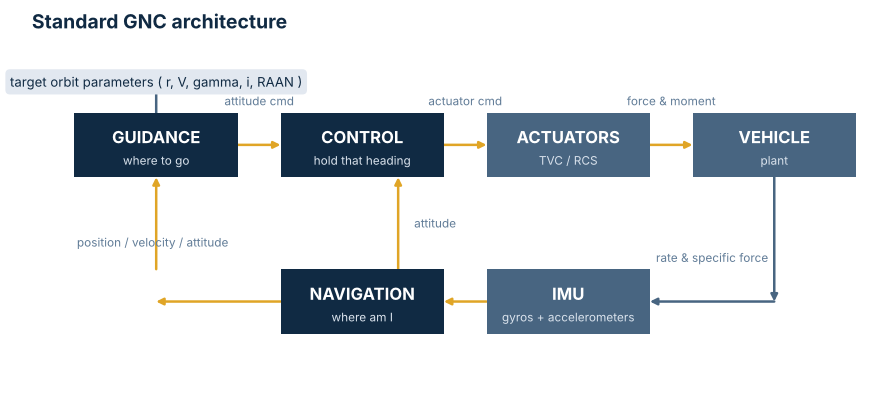

The dark-navy blocks (guidance, control, navigation) are NOT hardware:
they are functions inside the on-board computer's flight software.
Only the IMU, the actuators and the vehicle itself are physical.

Order matters: if navigation is wrong, guidance computes a correct answer to
the wrong question. Navigation performance therefore sets the UPPER BOUND on
insertion accuracy; guidance sophistication only operates inside that bound.


In [3]:
ex1_1_gnc_block()

## 1.2 내루프와 외루프: 왜 기능을 나누는가

- 설계의 출발점 = 대역폭이 다른 문제를 하나의 루프로 풀지 않음

| 구분 | 유도 (외루프) | 제어 (내루프) | 시퀀스 제어 |
|---|---|---|---|
| **다루는 물리량** | 위치·속도 벡터 (궤도 수준) | 자세각·각속도 (기체 수준) | 이산 사건 (단분리·점화) |
| **대표 주기** | 0.1 ~ 1 초급 | 수 ms ~ 수십 ms급 | 사건 기반(event-driven) |
| **목적함수** | 목표궤도 오차 최소화, 추진제 최소 소모 | 명령 추종, 자세 안정성 확보 | 정해진 순서·시각의 보장 |
| **실패의 결과** | 궤도 진입 실패 (임무 실패) | 기체 자세 발산 (즉시 상실) | 단분리 실패 등 치명적 사건 |
| **설계 도구** | 최적제어·궤적최적화 | 고전/현대 제어이론, 구조연성 해석 | 신뢰성·이중화 설계 |

### 주파수 분리(frequency separation)
- 내루프가 외루프보다 충분히 빠르면 → 유도는 제어 동역학 무시 가능
- 가정: **"명령한 자세는 즉시 실현된다"**
- 효과: 유도 문제를 **질점(point-mass) 궤적 문제**로 단순화

### 가정이 깨지는 지점
- 해당 조건: 추진제 슬로싱, 동체 굽힘모드(bending mode), 대형 저강성 기체
- 현상: 두 루프의 대역폭 접근
- → **초대형·재사용 발사체에서 GNC 설계가 어려워지는 근본 원인**

---
# 제2부 · 항법 (Navigation)

> 관성센서 · 스트랩다운 기법 · 오차 모델 · 초기정렬 · 위성항법 결합

## 2.1 항법 방식의 계보와 발사체의 선택

- 핵심 질문: 여섯 가지 항법 방식 중 발사체는 왜 관성항법을 택했는가

| 방식 | 원리 |
|---|---|
| 지문항법 (Piloting) | 지형지물을 눈으로 확인 |
| 추측항법 (Dead-Reckoning) | 침로·속력·시간으로 위치 추정 |
| 천측항법 (Celestial) | 천체 관측으로 절대위치 결정 |
| 전파항법 (Radio) | 지상국 전파를 기준으로 측위 |
| **관성항법 (INS)** | **가속도·각속도 적분으로 자립 측위** |
| **위성항법 (GNSS)** | **위성 신호로 절대위치 측정** |

| 특성 | 관성항법 (INS) | 위성항법 (GNSS) |
|---|---|---|
| 정확도 특성 | 단기 정확, 시간에 따라 열화 | 장기 안정, 단기 잡음 큼 |
| 초기조건 | **필수 (초기정렬)** | 불필요 |
| 자세 정보 | **제공** | 일반적으로 미제공 |
| 중력 영향 | 받음 (중력모델 필요) | 받지 않음 |
| 자립성 | 완전 자립 | 외부 신호 의존 |
| 재밍 내성 | 있음 | 없음 |
| 출력 주기 | 높음 (수백 Hz) | 낮음 (수 Hz) |

> **발사체가 관성항법을 택하는 세 조건**
> - 상승 구간이 10분 내외로 **짧음**
> - 외부 신호 의존 불가 (재밍·차폐·자세 급변)
> - **자세 정보가 제어에 필수**
> - → 세 조건이 겹치면 선택지는 관성항법 하나로 수렴
> - 위성항법 = '대체재'가 아닌 장기 드리프트를 억제하는 **'보강재'**

## 2.2 관성항법의 세 가지 구성요소

- 출발점: 센서가 주는 것과 **주지 않는 것**의 구분

1. **관성측정장치 (IMU)** — 자이로 3축(각속도) + 가속도계 3축(**비력** specific force)
   - 가속도계 = '가속도'가 아닌 **중력을 제외한 비중력 가속도**를 측정
   - 자유낙하 중인 가속도계의 출력 = 0
2. **초기조건** — 자세·속도·위치의 초기값
   - 적분기는 초기값 없이 아무것도 산출하지 못함
   - → 발사 전 **초기정렬(alignment)** 필요 (GNSS와의 결정적 차이)
3. **중력모델** — 가속도계가 측정하지 못하는 중력항 $\mathbf{g}$를 계산으로 보충
   - WGS-84 타원체 + 구면조화 전개($J_2\!\cdot\!J_3\!\cdot\!J_4$) 사용

$$\mathbf{a} = \frac{\mathbf{F}}{m} + \mathbf{g}$$

- 가속도계 출력 $\mathbf{F}/m$ + 중력모델 $\mathbf{g}$ = 관성좌표계 가속도
- 자세: 자이로 적분 / 속도·위치: 가속도의 1회·2회 적분
- 관성항법이 **'적분의 학문'** 으로 불리는 이유 = 오차가 시간에 따라 누적·증폭되는 구조적 원인과 동일

In [4]:
ex2_1_accel_vs_gravity()

== An accelerometer measures specific force, not gravity ==
                 State  Altitude [km]  Gravity g [m/s2]  Accelerometer output f = F/m [m/s2]   f - g
   On the pad (static)              0            9.8142                               9.8142  0.0000
             Free fall              0            9.8142                               0.0000 -9.8142
Powered ascent (1.5 g)            100            9.5131                              14.7100  5.1969
        Circular orbit            700            7.9666                               0.0000 -7.9666

-> In orbit the accelerometer reads zero. Integrate that without a gravity
   model and the satellite flies in a straight line.
-> From 0 to 700 km gravity drops 9.814 -> 7.967 m/s2 (18.8%). The model carries that change.


---
## 심화 2-A · 관성항법유도장치(INGU)의 해부

- 발사체 INS = 센서 6개 + 전자부 + 항법컴퓨터를 하나의 함체에 통합한 **항법·유도 일체형 장치**
- 누리호 명칭: **관성항법유도장치(INGU, Inertial Navigation & Guidance Unit)**
- 핵심 설계 쟁점 = 센서 성능보다 **센서가 놓이는 환경**의 통제

| 구성 | 역할 | 설계 쟁점 |
|---|---|---|
| **센서 블록** | 자이로 3축 + 가속도계 3축을 하나의 강체 블록에 고정 | 축간 정렬(µrad), 블록 강성, **온도 안정화** |
| **방진기 (isolator)** | 엔진·공력 진동을 센서로부터 차단 | 고유진동수를 제어 대역보다 충분히 높게 — 낮으면 자세제어 루프와 연성 |
| **센서 전자부** | 광원(FOG)·서보 루프(가속도계)·A/D 변환 | 잡음·양자화, 기준전압 안정도 |
| **항법컴퓨터** | 교정 보상 → 스트랩다운 적분 → 유도 연산 | 고속 연산, 결정론적 실행시간 |
| **전원·BIT** | 전원 공급, 자체 진단(Built-In Test) | 발사 전 점검 자동화 |
| **인터페이스** | 비행컴퓨터·원격측정·GNSS 수신기 연결 | MIL-STD-1553 / RS-422 등 |

> **읽는 포인트**
> - 오차의 상당 부분은 센서 자체가 아닌 **장착·온도·진동 환경**에서 발생
> - "센서를 사 오면 끝"이 아닌 이유 → 패키징·교정·보상 기술이 국산화의 실질적 내용

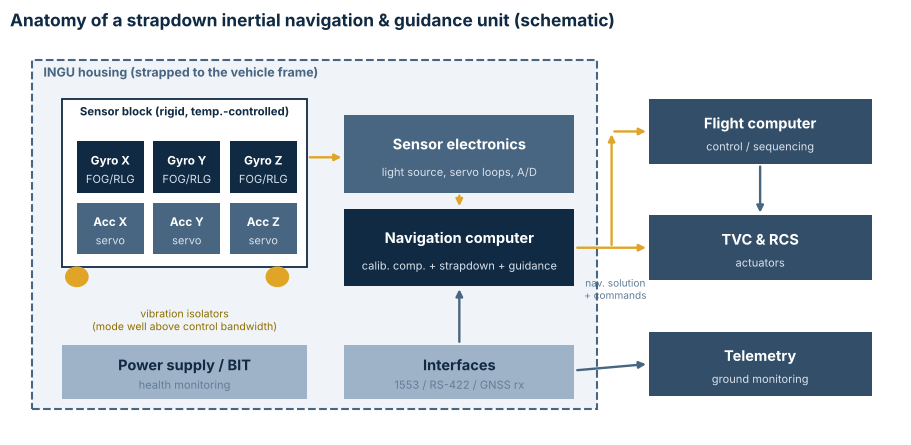

In [5]:
ins_anatomy()

## 2.3 가속도계: 힘을 변위가 아니라 전류로 읽는다

| 항목 | 개루프 (Open-Loop) | 폐루프 (force-rebalance) | 공학적 의미 |
|---|---|---|---|
| 측정량 | 변위 $x$ | 되먹임 전류 $i$ | 전기량은 정밀 측정이 용이 |
| 선형성 | 스프링 특성에 종속 | 되먹임 루프 이득에 종속 | 부품이 아닌 **회로**가 정밀도 결정 |
| 동적 범위 | 좁음 | 넓음 (±수십 g) | 이륙~최대가속을 단일 센서로 감당 |
| 대표 제품군 | MEMS 저가형 | 석영 진자식(Q-flex) 서보형 | 전략·항법급 IMU의 표준 부품 |

**개루프**: $F = m a = k x \;\Rightarrow\; a = (k/m)\,x$
- 검증질량이 스프링을 눌러 생긴 변위를 판독
- 스프링 상수의 비선형성·온도 의존성 → 그대로 측정오차
- 동적 범위 협소

**폐루프 진자식**: $T = F\,l = m a l = k_t i \;\Rightarrow\; a = \dfrac{k_t}{m l}\,i = K_s\, i$
- 검증질량이 움직이지 않도록 전자석이 되밀어줌 → **이때 흘린 전류**를 측정값으로 사용
- 질량이 원점 부근에 상주 → 넓은 동적 범위 + 우수한 선형성
- 현재 발사체용 가속도계의 표준

> **설계 원리: 영위법(null method)의 힘**
> - 측정 대상을 '움직이게 두고 읽는' 대신 '움직이지 못하게 하고 그 대가를 읽음'
> - 정밀도의 책임: 기계 부품 → 되먹임 회로로 이전



---
## 심화 2-B · 진자식 서보 가속도계의 구조와 동작

- 발사체·항법급 IMU의 표준 = **석영 진자식 서보 가속도계(Q-flex 계열)**
- 구조 요소
  - **검증질량(proof mass)**: 석영 힌지(flexure)에 매달린 진자
  - **픽오프(pick-off)**: 검증질량의 미소 변위를 정전용량으로 검출
  - **토커(torquer)**: 영구자석 + 코일, 전류로 검증질량을 원위치로 되밂
  - **서보 증폭기**: 변위 → 0이 되도록 전류 조절
- 출력 = 되먹임 전류 $i$ → 감지저항 전압으로 판독 → $a = K_s\, i$

| 비교 | 개루프 (스프링 판독) | 폐루프 (전류 판독) |
|---|---|---|
| 검증질량 변위 | 입력에 비례해 이동 (수백 µm) | **원점 부근 유지 (nm 수준)** |
| 비선형 오차 원인 | 스프링 비선형성이 그대로 출력 | 스프링이 거의 변형되지 않아 비선형성 미발현 |
| 정밀도 결정 요소 | 기계 부품 | 토커 계수 $K_s$의 안정도 (온도 보상 대상) |

### 역사적 계보: PIGA (진자식 적분 자이로 가속도계)
- 탄도미사일·Saturn V 세대의 고정밀 가속도계
- 진자의 가속도 토크를 **자이로 세차 운동**으로 상쇄 → 세차 각도 = 속도의 적분값
- 극한 정밀도, 그러나 크고 비싸며 기계식 → 현재는 전략급 일부에만 잔존

<table><tr><td align="center" valign="top" width="360"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/PIGA_accelerometer_1.png?width=720" width="360" alt="PIGA 가속도계 (진자식 적분 자이로 가속도계)"><br><sub>PIGA 가속도계 (진자식 적분 자이로 가속도계)<br><a href="https://commons.wikimedia.org/wiki/File:PIGA_accelerometer_1.png">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

- 아래 실습: 같은 10 g 계단 입력에서 두 방식의 검증질량 변위·판독값·비선형 오차 비교
- 슬라이더: 입력 가속도 크기 → 개루프 비선형 오차가 입력의 제곱으로 커지는 양상 확인

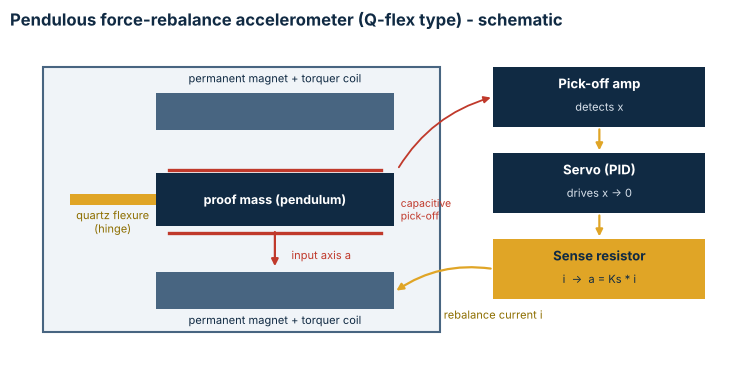

In [6]:
accel_schematic()

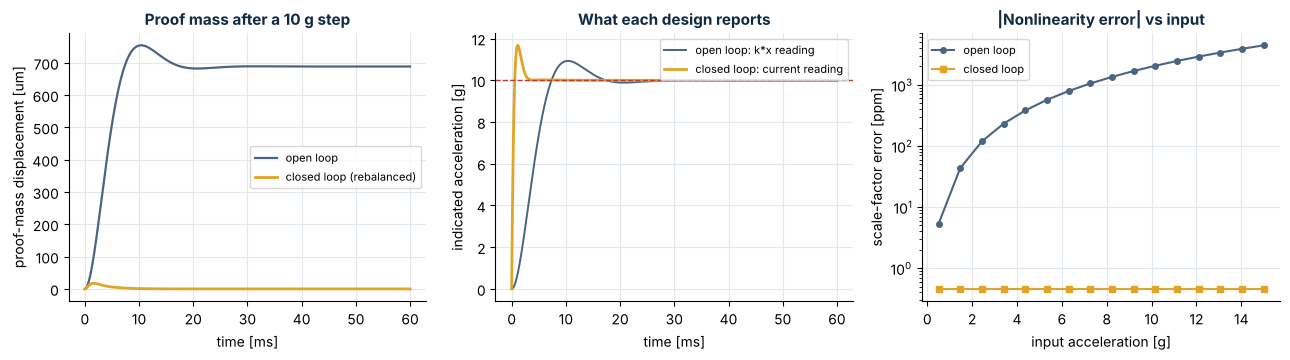

Spring nonlinearity model: k(x) = k0*(1 + 0.002*(x/x10g)^2).  At 10 g the open-loop mass moves 688.64 um,
the closed-loop mass only 0.00 nm -> the spring's nonlinearity is never exercised.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: a_step_g


In [7]:
widget_accel_servo()

## 2.4 자이로스코프: 세 가지 물리 원리

| 방식 | 대표 기술 | 원리 |
|---|---|---|
| **기계식 (Mechanical)** | FRIG · DTG | 회전자 각운동량 $H$가 입력 각속도에 저항하는 토크 생성: $T = H\Omega = (I_s\omega_s)\Omega = k_t\theta$ <br>부품 수 다수, 마모·수명 문제 <br>Saturn V·Space Shuttle 세대 |
| **광학식 (Optical)** | RLG · FOG | 회전 링에서 시계·반시계 방향 빛의 광로차 판독(**Sagnac 효과**): $\Delta L = 4A\Omega/c$ <br>가동부 없음 → 높은 신뢰성 <br>현재 발사체 항법의 주류 |
| **코리올리 진동식** | HRG · MEMS | 진동체에 작용하는 코리올리 힘으로 각속도 감지 <br>부품 수 극소 → 저비용·소형화 유리 |

### Sagnac 효과 — 회전을 '길이'로 변환하는 원리

$$\Delta t = \frac{2\pi R}{c-R\Omega} - \frac{2\pi R}{c+R\Omega} \approx \frac{4\pi R^2 \Omega}{c^2},
\qquad \Delta L = c\,\Delta t = \frac{4A\Omega}{c}$$

- 링 레이저 자이로(RLG): 광로차를 두 공진 주파수의 **맥놀이**로 판독 $\left(\Delta\nu = \dfrac{4A\Omega}{L\lambda}\right)$
- 광섬유 자이로(FOG): 광로차를 **위상차**로 판독 $\left(\Delta\phi = \dfrac{2\pi L D \Omega}{\lambda c}\right)$
- 공통: **감지 면적 $A$가 클수록 민감** → 크기와 성능의 교환 관계, 소형화의 물리적 한계

== Signal level when sensing Earth rotation (15 deg/h) ==
               Configuration Type  Sensing area A [cm2]  Path difference dL [fm] (1e-15 m)  Quantity read  Magnitude
       Small RLG (5 cm side)  RLG                25.000                              2.432 beat freq [Hz]      5.760
     Medium RLG (10 cm side)  RLG               100.000                              9.730 beat freq [Hz]     11.520
FOG (8 cm coil, 500 m fibre)  FOG                50.265                              4.891   phase [urad]     96.576

-> The path difference itself is 2-10 fm, the diameter of an atomic nucleus.
   It can never be read as a 'length'.
-> An RLG converts it to a beat FREQUENCY, a FOG to an optical PHASE.
-> The signal scales with the sensing area A: miniaturisation costs sensitivity,
   which is the physical reason MEMS gyros plateau far below navigation grade.


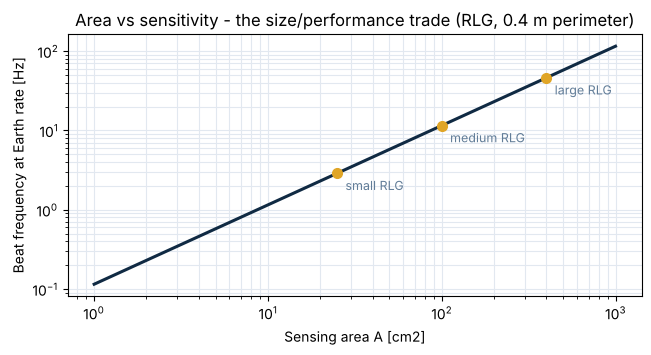

In [8]:
ex2_2_sagnac()

---
## 심화 2-C · 기계식 자이로: 동조 자이로(DTG)의 '동조 조건'

- 기계식 자이로의 숙제 = 회전자를 지지하는 **베어링·힌지의 구속 토크** → 드리프트 원인
- 해법의 진화
  - **부유식(FRIG)**: 회전자를 유체에 띄워 마찰 제거 (Saturn V ST-124-M의 AB5-K8: **가스 베어링**)
  - **동조식(DTG)**: 짐벌의 동적 효과로 힌지 스프링을 **상쇄**

### DTG의 원리
- 회전자는 탄성 힌지(flexure)와 짐벌을 통해 구동축에 연결
- 회전 중 짐벌의 관성이 **음(−)의 스프링**처럼 작용

$$K_{eff} = K_{flex} - J_g N^2 \quad\Rightarrow\quad K_{eff}=0 \ \text{ at } \ N_{tuned} = \sqrt{K_{flex}/J_g}$$

- 동조 회전수에서 회전자 = **자유 회전체**와 동등 → 순수한 자이로 강성만 남음
- 회전수 오차 → 잔류 강성 → 드리프트 → **스핀 모터 회전수 제어가 곧 자이로 정밀도**
- 적용: Space Shuttle KT-70, 나로호(KSLV-I) 등 1980~2000년대 주력

- 아래 실습: 회전수에 따른 유효 스프링·드리프트 → 동조점의 '날카로움' 확인

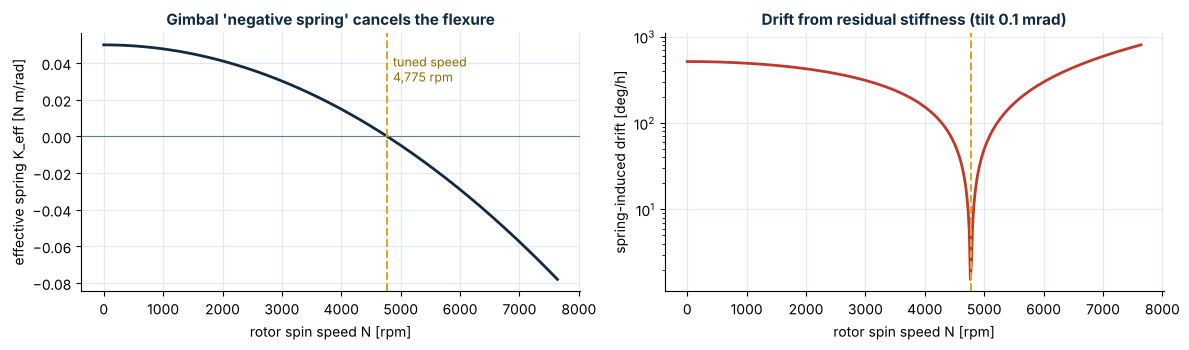

At the tuned speed the rotor behaves as if FREE (no restoring torque) -> pure gyroscopic rigidity.
A 0.1 % speed error leaves 0.2 % of K_flex -> spin-motor speed control is part of the gyro accuracy.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: K_flex, theta_mrad


In [9]:
widget_dtg()

---
## 심화 2-D · 링 레이저 자이로(RLG): 록인(lock-in)과 디더(dither)

<table><tr><td align="center" valign="top" width="330"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Ring_laser_gyroscope_at_MAKS-2011_airshow.jpg?width=660" width="330" alt="링 레이저 자이로 실물 (MAKS-2011 전시)"><br><sub>링 레이저 자이로 실물 (MAKS-2011 전시)<br><a href="https://commons.wikimedia.org/wiki/File:Ring_laser_gyroscope_at_MAKS-2011_airshow.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="330"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/KM-11-1A_laser_gyro_with_cover_removed.png?width=660" width="330" alt="덮개를 연 레이저 자이로 (KM-11-1A)"><br><sub>덮개를 연 레이저 자이로 (KM-11-1A)<br><a href="https://commons.wikimedia.org/wiki/File:KM-11-1A_laser_gyro_with_cover_removed.png">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

### 구조
- 삼각형(또는 사각형) 공진기를 **열팽창이 거의 없는 유리세라믹**(Zerodur 등) 블록에 가공
- He-Ne 가스 방전 → 시계·반시계 방향 두 레이저 빔이 동시 발진
- 회전 시 두 빔의 공진 주파수 차 = **맥놀이 주파수** $\Delta\nu = \dfrac{4A}{L\lambda}\Omega$
- 출력이 펄스(줄무늬 계수)로 나옴 → **본질적으로 디지털, 적분된 각도**를 직접 제공

### 록인 현상
- 거울의 미세한 후방산란 → 두 빔이 서로 '끌려가' 같은 주파수로 고정
- 결과: 작은 회전율($|\Omega| < \Omega_L$)에서 **출력 0 (불감대)**
- 모델(Adler 방정식): $\dot\psi = \Omega - \Omega_L \sin\psi$

### 해법: 기계식 디더
- 압전 소자로 자이로 블록 전체를 수백 Hz로 **비틀어 진동** → 대부분의 시간 동안 불감대 밖에 머묾
- 잔류 문제: 디더 주파수의 정수배에서 작은 계단(동적 록인) → **디더 진폭 무작위화**로 평활화
- 디더가 만든 진동은 신호처리로 제거 → 대가로 **랜덤워크(ARW) 증가**

- 아래 실습: 디더 진폭 0 → 불감대 / 진폭 증가 → 선형화 + 계단 잔류 관찰
- 대표 제품 예: Honeywell GG1320 (디지털 RLG), 다수 발사체·항공기 INS 탑재

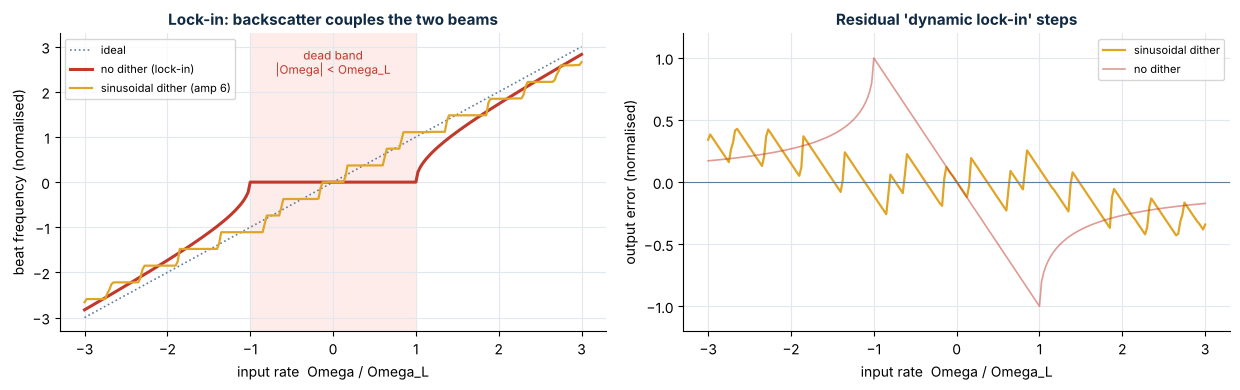

Model: d(psi)/dt = Omega + dither(t) - Omega_L*sin(psi)   (Adler equation, normalised by Omega_L)
Mechanical dither keeps the beams OUT of the dead band most of the time; the remaining steps
at multiples of the dither frequency are smeared out in real RLGs by randomising the dither amplitude.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: dither_amp


In [10]:
widget_rlg_lockin()

---
## 심화 2-E · 광섬유 자이로(FOG): 위상 변조와 코일 설계

<table><tr><td align="center" valign="top" width="420"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Fibre-optic-interferometer.svg?width=840" width="420" alt="광섬유 Sagnac 간섭계 개념도"><br><sub>광섬유 Sagnac 간섭계 개념도<br><a href="https://commons.wikimedia.org/wiki/File:Fibre-optic-interferometer.svg">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

### 구조
- 광원(초발광 다이오드, SLD) → 커플러 → **집적광학 칩**(편광·분기·위상변조) → 수백~수천 m **광섬유 코일**
- 코일을 시계·반시계로 돈 두 빛의 위상차 = Sagnac 위상

$$\phi_s = \frac{2\pi L D}{\lambda c}\,\Omega$$

- 레이저 공진이 아니므로 **록인 없음**, 가동부 없음 → 현재 발사체 항법의 주류 (누리호 포함)

### 왜 위상 변조가 필요한가
- 검출기 출력 $\propto 1+\cos\phi_s$ → 정지 부근에서 **기울기 0** → 감도·부호 상실
- 해법: 집적광학 위상변조기로 $\pm\pi/2$ 바이어스 변조 → 복조 출력 $\propto \sin\phi_s$ → 원점에서 최대 감도
- 폐루프 FOG: 위상을 되먹임으로 상쇄(serrodyne) → 스케일 팩터 선형성 확보

### 코일 설계의 교환관계
- 감도 ∝ **길이 × 직경** → 길게·크게 감을수록 정밀
- 대가: 크기·무게, 온도 구배에 따른 비상반 오차(Shupe 효과) → **대칭 권선(quadrupole)** 필요
- 항법급 0.01 °/h ↔ Sagnac 위상 약 $10^{-7}$ rad 수준의 측정

- 대표 제품 예: Northrop Grumman LN-200(전술급 FOG IMU), Exail(구 iXblue) 발사체용 INS
- 아래 실습: 코일 길이·직경을 바꿔 0.01 °/h에 해당하는 위상 크기 확인

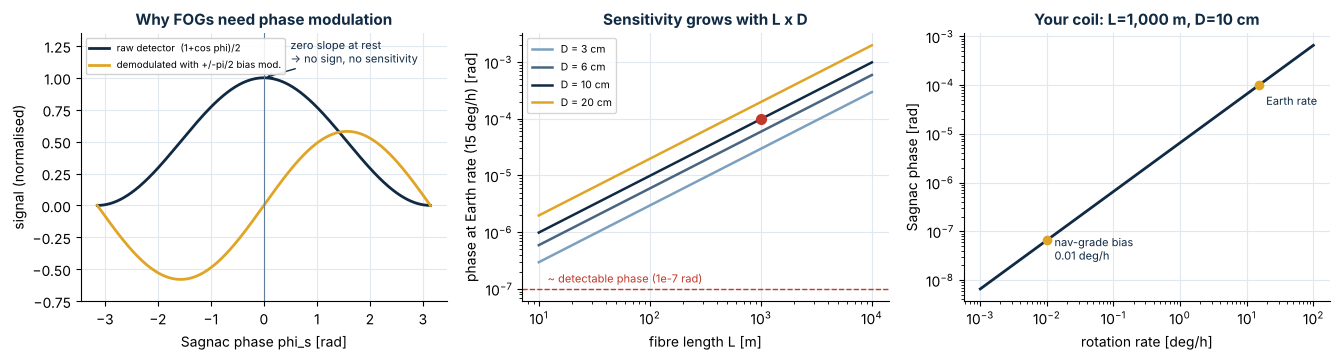

Scale factor = 2*pi*L*D/(lambda*c) = 1.352 rad per (rad/s).
A navigation-grade bias of 0.01 deg/h corresponds to only 6.6e-08 rad of phase -> the whole FOG is an exercise in measuring 1e-7 rad reliably.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: L_m, D_m


In [11]:
widget_fog()

---
## 심화 2-F · 반구공진 자이로(HRG): 와인잔의 정재파

<table><tr><td align="center" valign="top" width="360"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Hemispherical_Resonator_Gyroscope_(HRG).jpg?width=720" width="360" alt="반구공진 자이로(HRG) 공진기"><br><sub>반구공진 자이로(HRG) 공진기<br><a href="https://commons.wikimedia.org/wiki/File:Hemispherical_Resonator_Gyroscope_(HRG).jpg">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

### 원리 (Bryan 효과, 1890)
- 용융석영 반구(와인잔 형상)를 n=2 모드로 진동 → 4개의 마디·배를 갖는 **정재파**
- 반구가 회전하면 정재파는 그만큼 따라가지 못하고 **뒤처짐**
  - 케이스 대비 정재파 회전각 $= -k\,\Theta$ (Bryan 계수 $k \approx 0.3$, 얇은 링은 0.4)
- 정재파 각도 판독 = **회전각 직접 측정** (whole-angle 모드) — 적분 불필요

### 특징
- 가동부·마모 없음, 극저 잡음 → 장수명 위성·심우주 탐사선·전략급
- 공진기 품질계수 $Q$ 수천만 수준 → 초정밀 가공·도금·진공 밀봉 기술이 핵심
- 최근: 소형 HRG(Safran HRG Crystal 등)로 항법급 시장 진입 → FOG·RLG와 경쟁

- 아래 실습: 케이스 회전각·Bryan 계수를 바꿔 정재파 위치 변화 관찰

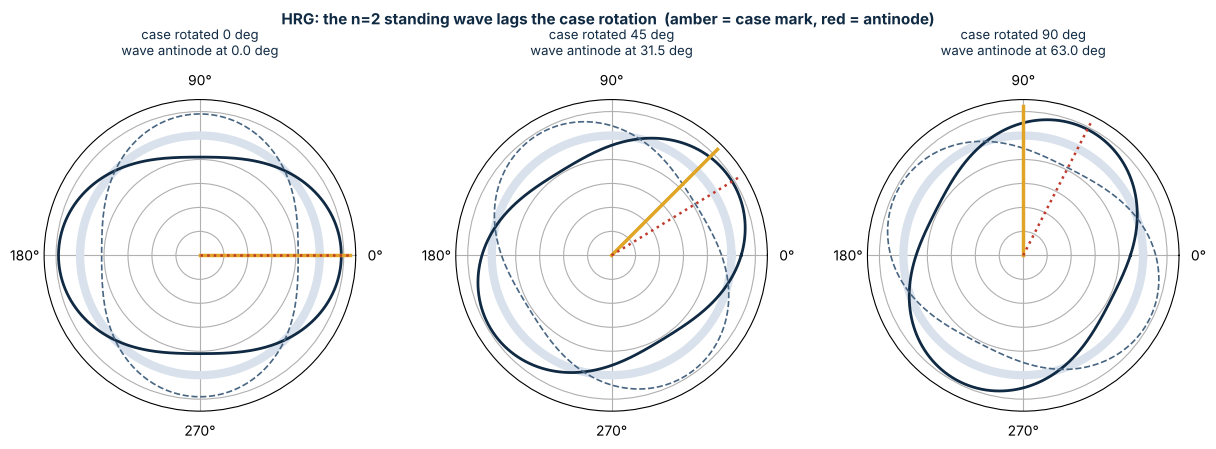

Pattern angle relative to the case = -k*Theta, k ~ 0.3 for a hemisphere (0.4 for a thin ring).
Reading the pattern angle gives the ROTATION ANGLE directly ('whole-angle' mode) - no rate integration,
no moving parts, no wear: the reason HRGs fly on long-life spacecraft.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: case_rot_deg, k_bryan


In [12]:
widget_hrg()

---
## 심화 2-G · MEMS 코리올리 자이로: 모드 정합의 딜레마

<table><tr><td align="center" valign="top" width="330"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/FreescaleSemiconductor_3-Axis-MEMS-Accelerometer_MMA8452Q_10953-01b.jpg?width=660" width="330" alt="MEMS 3축 가속도계 칩 (반도체 공정 관성센서의 예)"><br><sub>MEMS 3축 가속도계 칩 (반도체 공정 관성센서의 예)<br><a href="https://commons.wikimedia.org/wiki/File:FreescaleSemiconductor_3-Axis-MEMS-Accelerometer_MMA8452Q_10953-01b.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="330"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Schematic_diagram_of_disk_resonator_gyroscope.jpg?width=660" width="330" alt="MEMS 원판 공진 자이로(DRG) 개념도"><br><sub>MEMS 원판 공진 자이로(DRG) 개념도<br><a href="https://commons.wikimedia.org/wiki/File:Schematic_diagram_of_disk_resonator_gyroscope.jpg">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

### 원리
- 실리콘 미세구조를 **구동 모드**로 진동 → 회전 시 코리올리 힘 $\mathbf{F}_c = -2m\,\boldsymbol{\Omega}\times\mathbf{v}$
- 코리올리 힘이 직교 방향 **감지 모드** 진동을 유발 → 진폭 ∝ 회전율

### 모드 정합(mode matching)의 교환관계
- 감지 모드 주파수를 구동 주파수에 일치 → 감도가 $Q$배 증폭
- 대가: 대역폭 ≈ $f/2Q$ 로 축소 (느린 응답), 온도 변화에 따른 주파수 어긋남에 취약
- 모드 분리(split) 설계 → 빠르고 강건하나 감도 손실

| 구분 | 모드 정합 | 모드 분리 |
|---|---|---|
| 감도 | 높음 ($Q$배) | 낮음 |
| 대역폭 | 좁음 ($f/2Q$) | 넓음 (≈ 분리 주파수) |
| 온도 강건성 | 취약 | 양호 |

- 현황: 소비자·전술급 주력, 항법급 진입은 모드 정합 전자부·진공 패키징이 관건
- 정책적 의미: 반도체 공정 기반 → **저가·대량생산** → 소형 발사체·드론·유도무기 확산과 직결
- 아래 실습: 품질계수 $Q$·주파수 분리를 바꿔 감도-대역폭 교환 확인

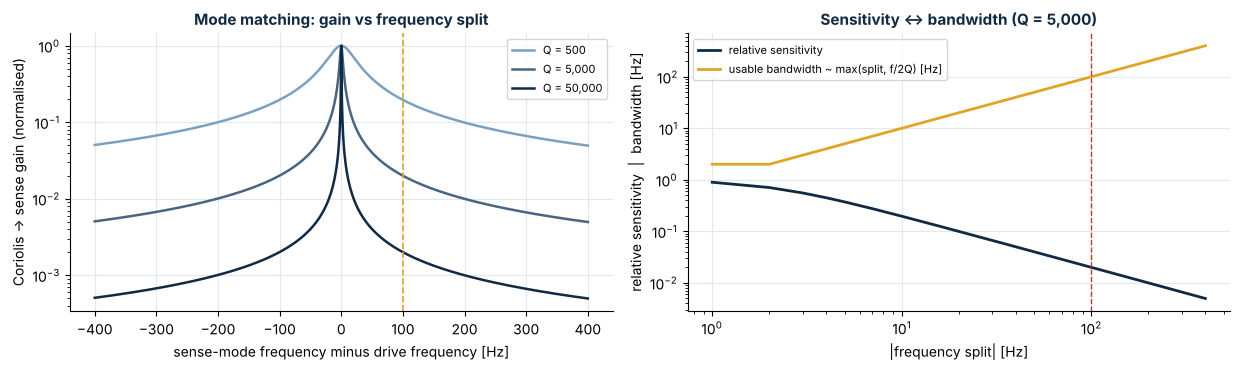

With a 100 Hz split the sensitivity is 1.99 % of the matched value, but the response is fast (~100 Hz bandwidth).
Matched + high Q = sensitive but slow and temperature-fragile -> why MEMS gyros sit in the tactical/consumer grade and why mode-matching electronics are the frontier.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: Q, split_hz


In [13]:
widget_mems()

## 2.5 자이로 기술의 진화: 부품 수가 곧 원가이자 신뢰성

- 부품 수 = 원가·조립공수·고장률·소형화 여지를 **동시에** 지배
- 40여 년간 부품 수 약 40배 감소 → 성능뿐 아니라 **산업구조 자체의 변화**

> **소형 발사체가 열린 배경**
> - 고성능 관성센서 = 전통적으로 수억 원대의 수출통제 품목
> - 진동식·MEMS 자이로 + GNSS 결합 → 진입장벽 하락
> - 결과: 현재의 소형 발사체 스타트업 확산

> **성능–비용의 교환은 여전히 유효**
> - 부유식·정전부유식(ESG), 반구공진(HRG): 최고 성능 영역 유지 (바이어스 안정도 0.0001 °/h 수준)
> - MEMS: 성능이 두세 자릿수 낮음
> - → **'싸진 센서' ≠ '충분한 센서'**

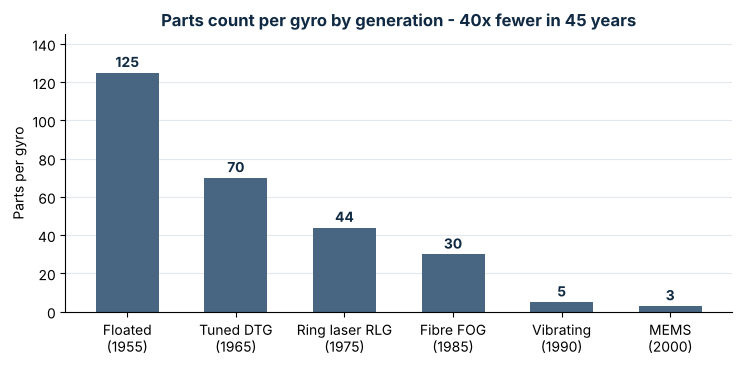

Floated -> MEMS: 125 -> 3 parts (42x fewer)


In [14]:
ex2_3_gyro_parts()

---
## 심화 2-H · 자이로 기술 지도: 바이어스 불안정도 vs 각도 랜덤워크

- 자이로 성능의 두 축
  - **바이어스 불안정도** (°/h): 장시간 드리프트 → 순수 관성비행 시간을 제한
  - **각도 랜덤워크, ARW** (°/√h): 단시간 잡음 → 정렬·자세 정밀도를 제한
- 좌하단일수록 고성능 → 기술별 영역과 등급 경계선을 함께 표시
- 수치는 공개 문헌의 **대표적 크기 차수(order)** 이며 특정 제품 규격 아님

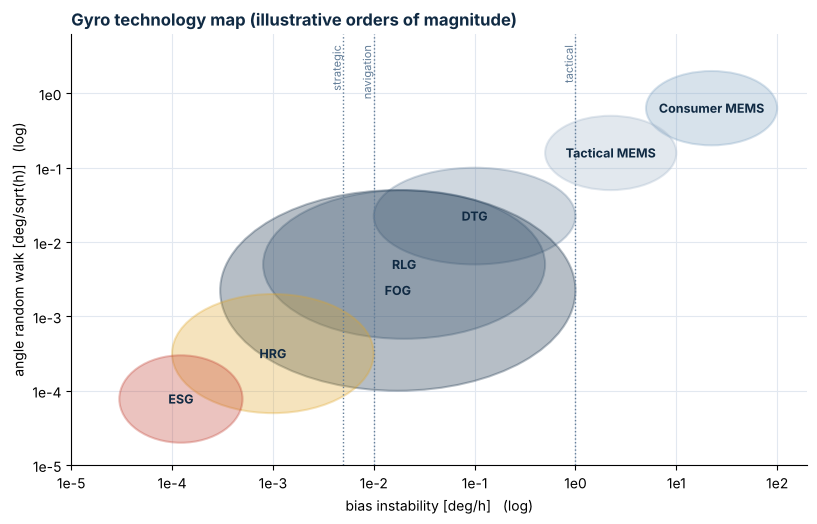

Lower-left = better. Launch vehicles live around the navigation-grade line (RLG/FOG);
MEMS is approaching it from the upper right, HRG/ESG hold the strategic corner.


In [15]:
gyro_tech_map()

## 2.6 짐벌식과 스트랩다운식

- 쟁점: **기계로 안정화할 것인가, 계산으로 안정화할 것인가**

| 구분 | 짐벌식 (Stable Platform) | 스트랩다운식 (Analytic Platform) |
|---|---|---|
| 구조 | 센서를 짐벌 위에 탑재, 항법좌표계에 상시 정렬 | 센서를 기체에 직접 고정, 짐벌을 **소프트웨어로 대체** |
| 핵심 계산 | 가속도계 출력을 그대로 적분 | 자이로로 좌표변환행렬 갱신 후 가속도 변환 |
| 크기·무게 | 대형 / 중량 (Saturn V 플랫폼 51 kg) | 소형 / 경량 |
| 충격·진동 | 기계부로 인해 취약 | 강함 (가동부 없음) |
| 장점 | 자체 교정(self-calibration) 가능, 절대성능 우수 | 경량·저비용, 이중화 용이 |
| **부담이 옮겨간 곳** | 정밀 기계가공, 서보 | **고속 연산, 수치적분 정확도** |

### 발사체별 채택 현황

| 짐벌식 · FRIG | 짐벌식 · DTG | 스트랩다운 · DTG | 스트랩다운 · RLG | 스트랩다운 · FOG |
|---|---|---|---|---|
| Saturn V, Atlas-Centaur, Ariane 1~4, Zenit, Proton, H-I, CZ-4 | Space Shuttle | Delta II, Taurus, Pegasus, PSLV, N-II, **나로호(KSLV-I)** | Atlas 5, Delta 4, Minotaur, Ariane 5, Vega, H-II/IIA, SLS | M-V, Falcon 1·9, CZ-8, **누리호(KSLV-II)** |

> - 1970년대까지 대형 발사체 = 짐벌식
> - 광학 자이로 등장 이후 신규 발사체 = 사실상 전량 스트랩다운으로 이행
> - 누리호: 국산 광섬유 자이로(KFG-1200) 기반 스트랩다운 채택

### 실물로 보는 플랫폼의 세대 변화

<table><tr><td align="center" valign="top" width="250"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/ST-124_inertial_platform.jpg?width=500" width="250" alt="Saturn V ST-124-M 3축 짐벌 안정 플랫폼"><br><sub>Saturn V ST-124-M 3축 짐벌 안정 플랫폼<br><a href="https://commons.wikimedia.org/wiki/File:ST-124_inertial_platform.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="250"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Apollo_IMU_at_Draper_Hack_the_Moon_exhibit.agr.jpg?width=500" width="250" alt="Apollo 우주선 IMU (MIT 계기연구소, 3축 짐벌)"><br><sub>Apollo 우주선 IMU (MIT 계기연구소, 3축 짐벌)<br><a href="https://commons.wikimedia.org/wiki/File:Apollo_IMU_at_Draper_Hack_the_Moon_exhibit.agr.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="250"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Space_Shuttle_IMU.jpg?width=500" width="250" alt="Space Shuttle IMU (4축 짐벌)"><br><sub>Space Shuttle IMU (4축 짐벌)<br><a href="https://commons.wikimedia.org/wiki/File:Space_Shuttle_IMU.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="250"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Peacekeeper_ICBM_Inertial_Measurement_Unit.jpg?width=500" width="250" alt="Peacekeeper ICBM 관성측정장치"><br><sub>Peacekeeper ICBM 관성측정장치<br><a href="https://commons.wikimedia.org/wiki/File:Peacekeeper_ICBM_Inertial_Measurement_Unit.jpg">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

- 공통점: 정밀 기계가공된 짐벌·베어링·서보 모터 → 수십 kg, 고가, 장시간 예열
- 이후 세대: 광학 자이로 + 스트랩다운 → 부품 수·무게 급감 (심화 2-D·2-E 참조)

## 2.7 항법 기준좌표계와 기계화 방정식

- 쟁점: 어느 좌표계에서 적분하는가 → 방정식의 형태가 달라짐

| 좌표계 | 정의 | 특징 |
|---|---|---|
| **ECI (관성좌표계)** | 지구 중심, 항성 기준 비회전 | 가장 단순: 자세 = 자이로 측정치 직접 적분, 속도 = 비력 + 중력. **발사체 상승 구간의 표준** |
| ECEF (지구고정좌표계) | 지구 중심, 지구와 함께 자전 | 코리올리 항 $-2\boldsymbol{\omega}\times\mathbf{v}$·원심력 포함. 지상 낙하점·비행안전 판단에 편리 |
| LVLH (국지수평좌표계) | 기체 위치의 지역 수평면 기준 | 위도·경도·고도 직접 산출. 항공기·재진입체에 적합, 극지 특이점 존재 |

### ECI 기계화 (스트랩다운)

$$\dot{C}_b^i = C_b^i\, \Omega_{ib}^b \qquad (\Omega \text{는 자이로 각속도의 반대칭 행렬})$$
$$\dot{\mathbf{v}}^i = C_b^i\, \mathbf{a}^b + \mathbf{g}^i \qquad (\text{기체좌표 비력을 관성좌표로 변환 후 중력 가산})$$
$$\dot{\mathbf{r}}^i = \mathbf{v}^i$$

## 2.8 자세는 어떻게 표현하는가

| 표현법 | 파라미터 | 특이점 | 특징 | 용도 |
|---|---|---|---|---|
| 오일러각 | 3 | 2번째 회전각 ±90°에서 발생 | 미분방정식에 삼각함수 포함, 가속도 변환 시 방향코사인으로 재변환 필요 | 사람이 읽는 출력(피치·요·롤) |
| 방향코사인행렬 (DCM) | 9 | 없음 | 가속도 변환식에 직접 사용 가능. 9개 성분에 6개 직교 구속조건 → 중복 큼 | 좌표변환 연산 |
| **쿼터니언** | **4** | **없음** | 미분방정식 형태가 DCM과 유사, 파라미터는 절반 이하. 정규화만 유지하면 수치적으로 안정 | **자세 적분의 실제 구현** |

**오일러의 주회전 정리**
- 강체의 임의 자세 변화 = 하나의 주축 $\hat{e}$ 둘레로 하나의 주각 $\Phi$만큼 회전한 것으로 표현 가능
- 쿼터니언 = 이 $(\hat{e}, \Phi)$를 4개의 정규화된 성분으로 옮긴 것

> **특이점이 실제 문제가 된 사례**
> - Saturn V: 3축 짐벌 플랫폼, 요각 ±90°에서 짐벌락 → 중간 짐벌 ±45° 제한
> - Space Shuttle: 4축 짐벌 채택의 이유
> - 스트랩다운 + 쿼터니언: 제약 자체를 제거

After 200 s:  altitude =   188.3 km,  inertial speed =  3122.0 m/s,  body-axis tilt = 47.5 deg
Quaternion norm error = 0.00e+00  (stays ~1e-12 or below when normalised)
-> Altitude and speed are recovered from gyro + accelerometer output ONLY.
   Accuracy depends entirely on (i) initial attitude q0, (ii) sensor errors, (iii) the gravity model.


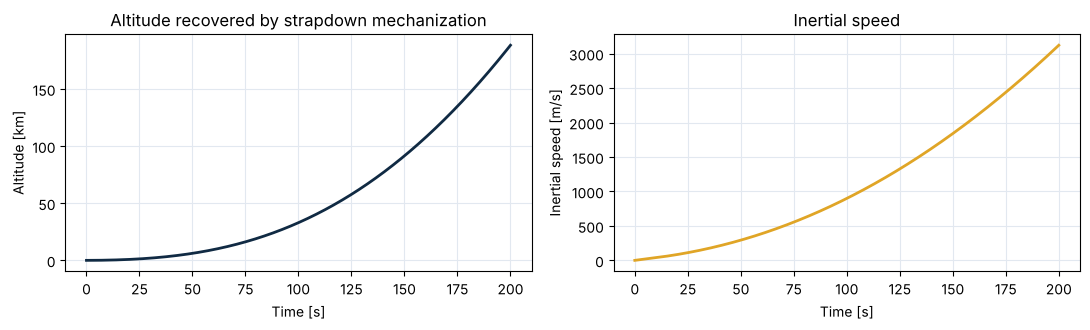

In [16]:
ex2_4_strapdown()

---
## 심화 2-I · 코닝(coning)과 2-샘플 자세 알고리즘

- 스트랩다운의 숨은 함정: **회전의 비가환성**
  - 두 축이 90° 위상차로 진동(코닝 운동) → 각 축 평균은 0
  - 그러나 기체는 세 번째 축 둘레로 **실제로 꾸준히 회전**
- 단순 알고리즘(각 증분을 그대로 합산) → 이 회전을 놓침 → **가짜 드리프트**
- 해법: 자세 갱신 주기 안의 두 각 증분 $\Delta\boldsymbol\theta_1, \Delta\boldsymbol\theta_2$로 보정

$$\boldsymbol\phi = \Delta\boldsymbol\theta_1 + \Delta\boldsymbol\theta_2 + \tfrac{2}{3}\,\Delta\boldsymbol\theta_1 \times \Delta\boldsymbol\theta_2$$

- 같은 원리의 속도 측 오차 = **스컬링(sculling)**: 회전 + 가속 진동의 결합 → 속도 드리프트
- 발사체 의미: 엔진 진동·구조 모드가 코닝/스컬링을 유발 → **센서 출력률·알고리즘 차수**가 항법 정밀도 결정
- 아래 실습: 코닝 주파수·진폭·갱신율을 바꿔 1-샘플 vs 2-샘플 오차 비교

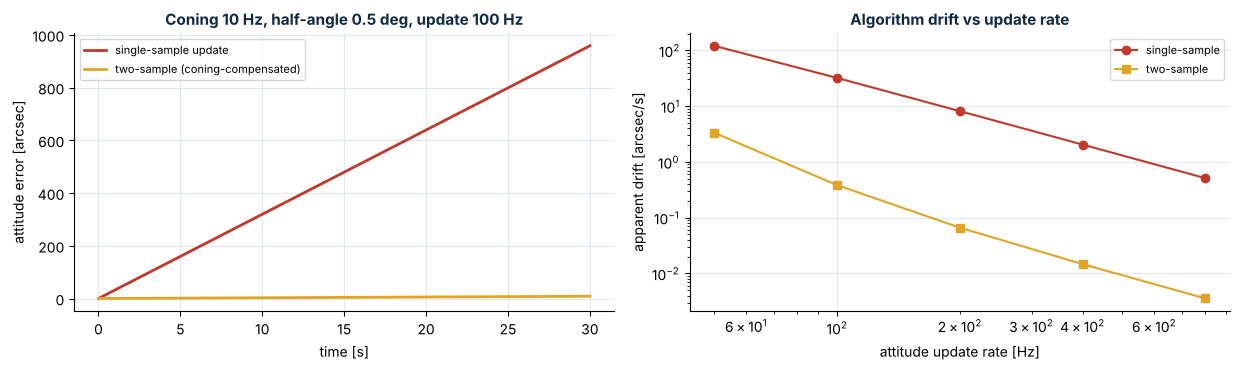

Coning = two axes oscillating 90 deg out of phase. Each axis averages to zero, yet the body
rotates steadily about the third axis (non-commutativity). An algorithm that just adds angle
increments misses this and DRIFTS. The 2/3*(d1 x d2) cross-product term recovers it.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: f_cone, half_deg, f_upd


In [17]:
widget_coning()

---
## 심화 2-J · 오일러각 특이점: 짐벌락의 수학

- 오일러각 미분방정식: 오일러각 변화율 = 기체 각속도 / $\cos\theta$
- $\theta \to 90°$ 에서 분모 → 0 → **무한대 각속도 요구 = 짐벌락**
- 짐벌식 플랫폼에서는 물리적 짐벌이 실제로 잠김 → Saturn V의 ±45° 운용 제한, Shuttle의 4축 짐벌
- 스트랩다운 + 쿼터니언 → 특이점 자체가 없음

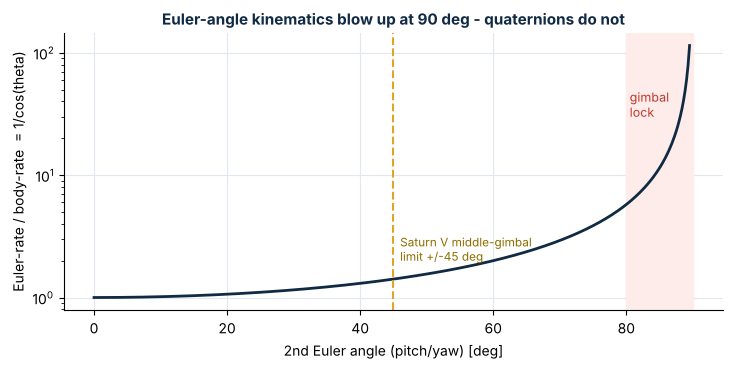

Euler-rate = body-rate / cos(theta): at 80 deg already 5.8x, at 89 deg 57x -> numerical blow-up.


In [18]:
euler_singularity()

## 2.9 관성센서의 오차원(誤差源)

- 쟁점: 무엇이 **반복 가능한** 오차이고, 무엇이 그렇지 않은가

| 오차원 | 내용 |
|---|---|
| **바이어스 (Bias)** | 입력 0에서도 잔존하는 출력. 자이로 °/h, 가속도계 µg·mg 단위. **항법오차의 지배적 원인** |
| 스케일 팩터 (Scale Factor) | 참 입력에 비례해 증가하는 오차. 대추력 구간 등 입력이 큰 시점에서 영향 증대 |
| 비선형성·비대칭 | 입출력 관계의 직선 이탈, +/− 방향 기울기 차이 |
| 축 비정렬 (Misalignment) | 센서 감지축과 설계 기준축 간 어긋난 각도. µrad 단위 관리 |
| 잡음 (Noise) | 백색잡음·양자화잡음·플리커잡음 등 확률적 성분. **교정으로 제거 불가** |

$$\delta\boldsymbol{\omega} = \mathbf{B} + [\,SF,\ MA\,]\cdot\boldsymbol{\omega} + \boldsymbol{\eta}$$

> **반복 가능성이 기준선**
> - 반복 가능(repeatable) 오차 → 교정(calibration)으로 모델링·보상 가능
> - 반복 불가 성분 = **바이어스 불안정도 + 잡음** → 실제 항법 성능의 한계 결정

### Allan 분산 도표 읽기
- 평균화 시간 $\tau$에 대한 표준편차를 로그–로그로 도시 → **기울기별로 오차 성분 분리**

| 기울기 | 오차 성분 |
|---|---|
| $-1$ | 양자화잡음 |
| $-1/2$ | **각도 랜덤워크 (ARW)** |
| $0$ | **바이어스 불안정도** |
| $+1/2$ | 각속도 랜덤워크 |
| $+1$ | 각속도 램프 |

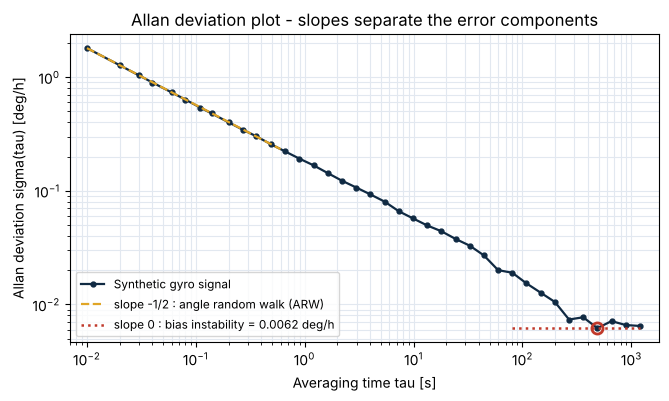

Plot minimum (bias instability) = 0.0062 deg/h  at tau = 488 s
-> This floor cannot be removed by calibration. Navigation specs are written against it.


In [19]:
ex2_5_allan()

## 2.10 관성항법장치의 성능 등급

- 등급 = 기술 분류이자 **수출통제의 분류**

| 등급 | 위치 성능 | 자이로 바이어스 | 가속도계 바이어스 | 자이로 기술 | 주요 적용 |
|---|---|---|---|---|---|
| 전략급 (Strategic) | 1 nmi / 24h | < 0.005 °/h | < 30 µg | ESG, RLG, FOG | ICBM, SLBM, 전략 자산 |
| **항법급 (Navigation)** | **1 nmi / h** | **0.01 °/h** | **50 µg** | RLG, FOG | **우주발사체**, 여객기 |
| 전술급 (Tactical) | > 10 nmi / h | 0.1 ~ 1 °/h | 1 mg | RLG, FOG | 전술 유도무기, 소형 발사체 |
| AHRS급 | — | 1 ~ 10 °/h | 1 mg | RLG, FOG, MEMS, 코리올리 | 자세방위 기준장치 |
| 제어급 (Control) | — | 10 ~ 1000 °/h | 10 mg | 코리올리 (MEMS) | 자세제어 보조, 상용 기기 |

> **발사체가 항법급이면 충분한 이유**
> - 발사체의 순수 관성비행 = 길어야 15~20분
> - 24시간 항행하는 잠수함과 달리 **오차 누적 시간이 짧음**
> - → 전략급 불필요, 항법급으로 요구 정확도 충족

> **정책적 함의: 이중용도의 정면**
> - 항법급 이상 관성센서 = MTCR 부속서·각국 수출통제 목록의 대표 통제 품목
> - 발사체 GNC 국산화 = '있으면 좋은 것'이 아닌 **'없으면 개발이 멈추는 것'**

## 2.11 자이로 바이어스는 어떻게 위치오차로 자라는가

- 적분 구조가 만드는 $t,\ t^2,\ t^3$ 성장 = **항법 성능 요구의 근거**

$$\delta\theta = \delta\omega_B\, t, \qquad
  \delta V = \tfrac{1}{2}\, g\, \delta\omega_B\, t^2, \qquad
  \delta p = \tfrac{1}{6}\, g\, \delta\omega_B\, t^3$$

- 메커니즘: 자세오차 발생 → 중력벡터가 수평 성분으로 누설($g\,\delta\theta$) → **가짜 수평가속도** 발생 → 재적분

실용 환산
- $\delta V \approx 0.0855\ \mathrm{(m/s)}\,/\,\mathrm{(°/h)}\,/\,\mathrm{min^2}$
- $\delta p \approx 1.71\ \mathrm{m}\,/\,\mathrm{(°/h)}\,/\,\mathrm{min^3}$

Rule-of-thumb check:  dV = 0.0856 (m/s)/(deg/h)/min^2    dp = 1.712 m/(deg/h)/min^3
== Error after 15 min (900 s) of pure inertial flight ==
   Nuri INGU spec: attitude 0.1 deg, velocity 3.0 m/s, position 1.5 km
 Gyro bias [deg/h]  Attitude err [deg]  Velocity err [m/s]  Position err [km]           Grade
             0.005              0.0012              0.0963             0.0289       Strategic
             0.010              0.0025              0.1926             0.0578      Navigation
             0.020              0.0050              0.3851             0.1155      Navigation
             0.050              0.0125              0.9628             0.2888 Tactical (edge)
             0.100              0.0250              1.9255             0.5777        Tactical
             1.000              0.2500             19.2553             5.7766            AHRS


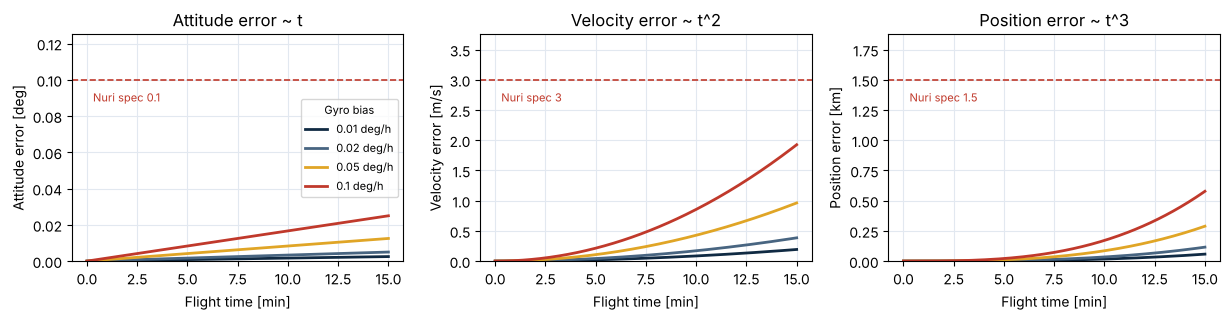


-> After 15 min, 0.01 deg/h gives about 58 m and 0.10 deg/h about 578 m of position error.
-> One sensor grade can decide whether the payload reaches orbit.

[Caution] These formulas assume a static, level platform. In flight, thrust acceleration,
          frame transformation and alignment error also act. Use them for order-of-magnitude
          intuition when setting requirements, not as a flight prediction.


In [20]:
ex2_6_error_growth()

---
## 심화 2-K · 항법 오차 예산: 무엇이 지배하는가

- 실제 발사 비행에서 자세오차가 곱해지는 대상 = 중력이 아닌 **측정 비력 $f$ (추력 가속도)**
  - 자세오차 $\boldsymbol\varepsilon$ → 가짜 가속도 $\boldsymbol\varepsilon \times \mathbf{f}$
- 오차원별 성장 모델 (단순화)

| 오차원 | 위치오차 성장 |
|---|---|
| 자이로 바이어스 $\delta\omega$ | $f\,\delta\omega\, t^3/6$ |
| 가속도계 바이어스 $b$ | $b\, t^2/2$ |
| 가속도계 스케일 팩터 $SF$ | $SF \cdot f\, t^2/2$ |
| 초기 방위각 정렬오차 $\varepsilon_{az}$ | $\varepsilon_{az} \cdot f\, t^2/2$ |

> **발사체에서의 결론 (기본값 기준)**
> - 비행시간 10분 내외 → $t^3$ 항(자이로 바이어스)보다 $t^2$ 항(**정렬·가속도계**)이 지배
> - 누리호 INGU가 방위각 정렬 0.025°(3σ)를 별도 규격으로 관리하는 이유
> - 비행시간이 길어질수록(상단 관성비행, 재점화) 자이로 바이어스 비중 급증 → 슬라이더로 확인

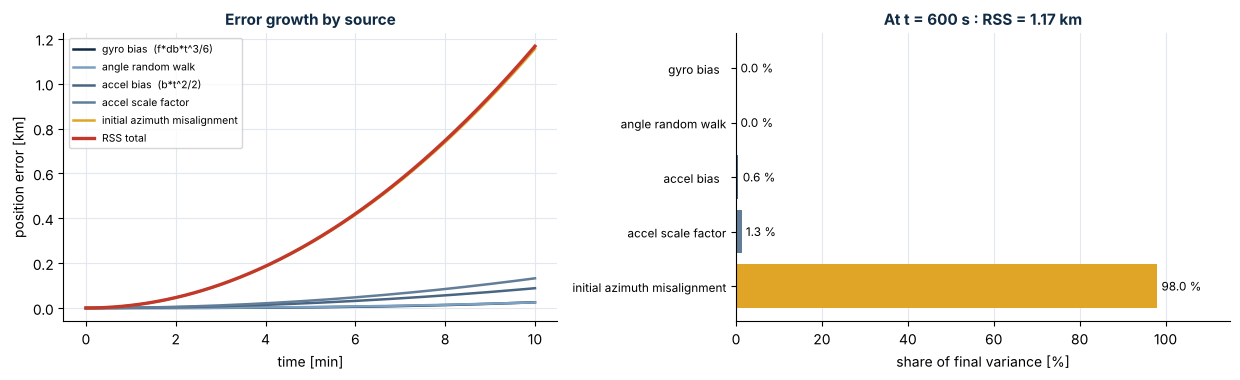

Tilt errors rotate the measured specific force f (mean 1.5 g of thrust), not gravity:
an attitude error eps creates a false acceleration eps x f.  With the defaults, the launch-pad azimuth
alignment dominates - the reason Nuri's INGU carries a dedicated 0.025 deg (3 sigma) alignment spec.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: t_flight_s, gyro_bias_dph, acc_bias_ug, sf_ppm, align_az_deg


In [21]:
widget_nav_budget()

---
## 심화 2-L · 슐러 진동과 불안정한 수직 채널

- 관성항법은 중력모델을 통해 **스스로 되먹임 루프**를 형성
- **수평 채널** — 안정
  - 위치오차 → 중력벡터 방향 오차 → 오차를 되돌리는 방향의 가짜 가속도
  - 결과: 주기 $2\pi\sqrt{R/g} \approx$ **84.4분**의 유계 진동 (슐러 진동)
- **수직 채널** — 불안정
  - 고도 과대추정 → 모델 중력 감소 → 더 위로 가속 → 오차 확대
  - 결과: 시정수 $\sqrt{R/2g} \approx$ **570초**의 지수 발산

| 채널 | 오차 동역학 | 결과 |
|---|---|---|
| 수평 | $\ddot{\delta x} = -\dfrac{g}{R}\,\delta x + b$ | 유계 진동 (84.4 min) |
| 수직 | $\ddot{\delta h} = +\dfrac{2g}{R}\,\delta h + b$ | 지수 발산 (τ ≈ 570 s) |

> **발사체에의 함의**
> - 10분 상승 구간에서 슐러 효과는 미미 → 수평 오차 ≈ $\tfrac12 b t^2$ 근사 유효
> - 수직 채널 발산은 비행 후반부터 의미 → 장시간 비행·재사용 착륙 시 **GNSS·고도계 보강** 필요

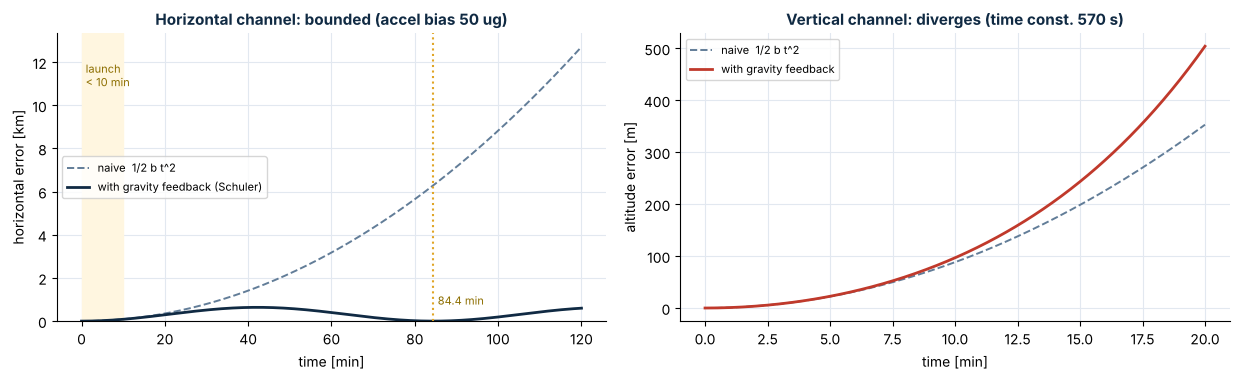

Schuler period 2*pi*sqrt(R/g) = 84.5 min: a horizontal tilt error makes gravity pull
the solution BACK -> bounded oscillation. Vertically, an altitude error lowers the modelled gravity,
which pushes the solution further away -> exponential growth with time constant sqrt(R/2g) = 570 s.
At 10 min: vertical error is 1.10x the naive value.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: acc_bias_ug


In [22]:
widget_schuler()

## 2.12 교정(Calibration)과 초기정렬(Alignment)

- **발사 전에 이미 절반은 결정됨**

### ① 교정 — 반복 가능한 오차의 표(모델)화

| 방식 | 내용 |
|---|---|
| **직접법 (Direct)** | 정밀 회전대에서 알려진 각속도 입력(**회전시험, rate test**) + 중력벡터에 대해 6~24개 자세 설정(**다위치시험, multi-position test**) → 계수를 직접 비교·추정 |
| **간접법 (Indirect)** | 각 축 180° 회전 전후의 속도·자세 오차로부터 계수 역추정 <br>- 장점: 시간 단축, 회전대 설치오차에 둔감, 정밀 각속도 모드 미사용으로 장비 수명에 유리 <br>- 단점: 항법 연산·데이터 처리 복잡 |

### ② 초기정렬 — 기준좌표계 대비 초기 자세 확정

| 단계 | 원리 | 산출물 |
|---|---|---|
| **개략정렬 (Coarse)** | 정지 상태 평균 가속도계 출력 = **중력벡터**, 자이로 출력 = **지구자전 각속도** 지시 <br>→ 두 기지 벡터를 기체좌표 관측값과 대조하여 방향코사인행렬을 해석적으로 계산 | 초기 DCM (개략) |
| **정밀정렬 (Fine)** | 확장칼만필터로 상태 추정 <br>정지 상태에서 참값이 0인 **수평 속도오차** $(\delta V_n, \delta V_e)$를 관측량으로 사용하여 자세 보정 | 정밀 초기자세 + 센서 바이어스 추정치 |

> **방위각 정렬의 한계**
> - 지구자전 각속도 = **15 °/h에 불과**
> - 자이로컴퍼싱만으로 방위각 정렬 시 센서 바이어스가 이보다 훨씬 작아야 함
> - → 발사체는 통상 발사대에서 **광학 정렬(optical alignment)** 로 방위각을 별도 주입
> - 누리호 INGU 방위각 정렬 요구: **0.025°(3σ)**

In [23]:
ex2_7_alignment()

Earth rate = 15.041 deg/h,  horizontal component at 34.43 deg N = 12.406 deg/h
== Can azimuth be set by gyrocompassing alone? ==
     Grade  Gyro bias [deg/h]  Azimuth error [deg]         Meets Nuri 0.025 deg?
 Strategic              0.005               0.0231                            OK
Navigation              0.010               0.0462 NO (optical alignment needed)
  Tactical              0.100               0.4618 NO (optical alignment needed)
      AHRS              1.000               4.6234 NO (optical alignment needed)

-> Even a navigation-grade 0.01 deg/h gyro gives 0.046 deg, above the 0.025 deg requirement.
-> That is why launchers inject azimuth by OPTICAL alignment (theodolite) on the pad.

== Coarse alignment accuracy (TRIAD) vs gyro bias ==
  gyro bias 0.000 deg/h  ->  attitude estimate error  0.0000 deg
  gyro bias 0.010 deg/h  ->  attitude estimate error  0.0355 deg
  gyro bias 0.100 deg/h  ->  attitude estimate error  0.3547 deg


## 2.13 위성항법 보강 관성항법 (GNSS-aided INS)

- 전통: 발사체 항법 = 순수 관성 (외부 신호 비의존이 최대 장점)
- 변화 요인
  - 고성능 센서의 고가·수출통제 부담
  - 저비용 소형 발사체의 확산
  - **재사용 발사체의 착륙 요구**
- → 중급 관성센서 + GNSS 결합이 표준적 대안으로 부상

| 결합 방식 | 사용하는 측정치 | 장점 | 단점 |
|---|---|---|---|
| **느슨한 결합 (Loosely)** | 수신기 출력(위치·속도·시각, PVT) | 구현 단순, 센서 호환성 우수 | 위성 4기 이상 확보 전제 |
| **강한 결합 (Tightly)** | 의사거리·의사거리율·반송파 위상 등 **원시 측정치** | 위성 4기 미만에서도 동작 | 수신기 내부 접근 필요 |
| **심결합 (Deeply)** | 수신기 누적 상관기 출력 $(I, Q)$ | 성능·강건성 최우수 | 최고 복잡도, 통합 설계 필요 |

**개루프 vs 폐루프 융합**
- 개루프: 관성 해에 보정량을 가산하여 사용
- 폐루프: 관성 적분 자체를 융합 추정치로 주기적 **재설정**
  - 상태가 원점 근처에 상주 → 선형화 오차·수치 문제 감소

> **재사용 발사체의 요구**
> - 1단 회수 → 지상 착륙점에 **미터급** 접근 필요
> - 관성 + GNSS만으로 부족 → 전파고도계 등 추가 항법 센서 요구
> - 항법 문제가 상승 구간을 넘어 **하강·착륙 구간**으로 확장

After 900 s:  pure INS position error =      195.8 m
              INS/GNSS coupled        =        0.6 m
Bias estimate: true 50.0 ug -> estimated 47.1 ug


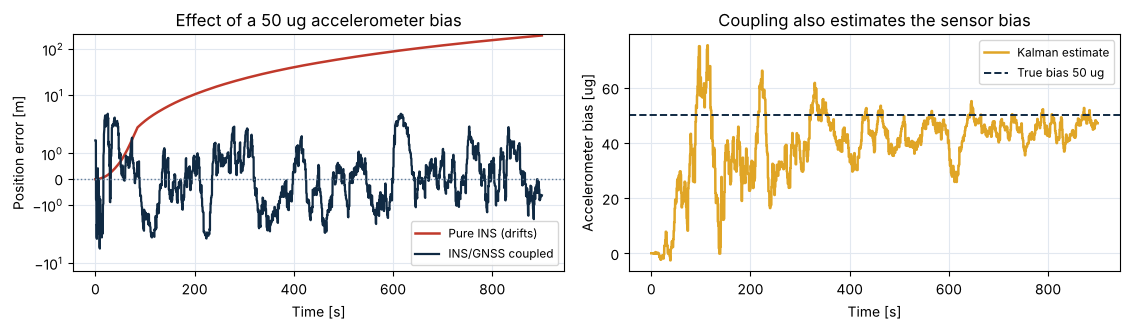


-> The point of coupling is not to 'fix the position' but to ESTIMATE and remove the error source.
   That is why performance holds for a while even after GNSS is lost (coasting).


In [24]:
ex2_8_ins_gnss_kf()

---
## 2.14 이중화와 고장검출: 경사 배치 센서

- 단일 IMU 고장 = 임무 상실 → 유인·고신뢰 발사체는 **센서 이중화** 필수
- 방식 비교
  - **IMU 다중화**: Space Shuttle — IMU 3대, 다수결 선정
  - **경사 배치(skewed)**: 하나의 블록에 센서 4~6개를 비직교 방향으로 배치 → 적은 센서로 고장 검출·격리

| 센서 수 | 고장 검출 | 고장 격리 | 비고 |
|---|---|---|---|
| 3 (직교) | 불가 | 불가 | 최소 구성 |
| 4 | 1개 | 불가 | — |
| 5 | 2개 | 1개 | — |
| 6 (정십이면체 면법선) | 2개 | 1개 | fail-operational / fail-safe |

### 패리티(parity) 기법
- 측정식 $\mathbf{m} = H\boldsymbol\omega + \boldsymbol\epsilon$ 에서 $V H = 0$ 인 행렬 $V$ 구성
- 패리티 벡터 $\mathbf{p} = V\mathbf{m}$ → **실제 운동은 상쇄, 센서 오차만 잔류**
- 임계값 초과 → 고장 검출, $\mathbf{p}$의 방향 → 고장 센서 격리
- 덤: 센서 수 $n$ 증가 → 3축 잡음 $\sigma\sqrt{3/n}$ 로 감소

- 아래 실습: 6번 중 3번 자이로에 고장 주입 → 패리티 벡터로 검출·격리

== Skewed redundant gyro configurations (sigma = single-sensor noise) ==
Configuration 3-axis rate noise   Detect                       Isolate
    3 sensors       1.000 sigma       no                            no
    4 sensors       0.866 sigma  1 fault                            no
    5 sensors       0.816 sigma 2 faults                       1 fault
    6 sensors       0.707 sigma 2 faults 1 fault (fail-op / fail-safe)


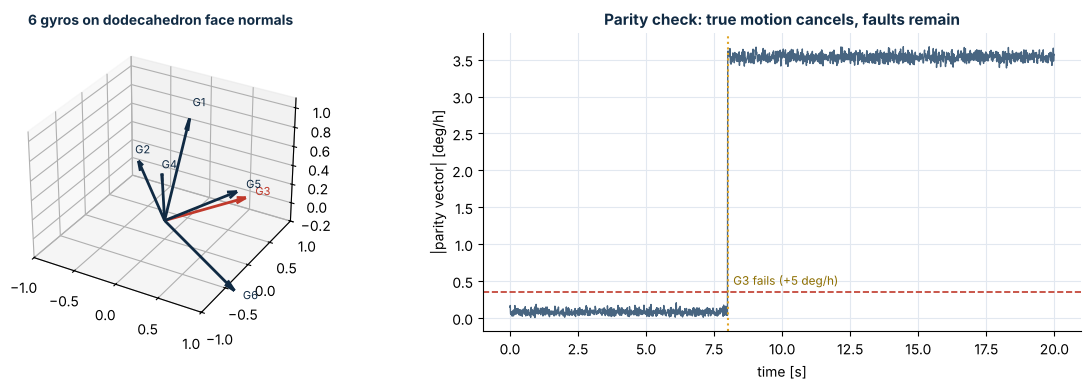

Isolation (largest projection of the mean parity vector onto each sensor's parity direction): G3
Noise falls as sqrt(3/n); with 6 skewed sensors any single fault is isolated and a second is detected.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: fault_dph


In [25]:
widget_redundancy()

---
# 제3부 · 유도 (Guidance)

> 비행 단계 · 오차 예산 · 하중경감 · 최적조향법칙 · 폐루프 알고리즘

## 3.1 이륙에서 궤도투입까지: 유도의 관점에서 본 비행 단계

| # | 단계 | 유도의 역할 |
|---|---|---|
| 1 | 수직 상승 (Vertical Rise) | 발사대 이탈·탑 회피. 자세 유지만 수행, 궤적 최적화 없음 |
| 2 | 방위각 롤 (Roll Program) | 목표 궤도경사각에 맞는 발사 방위각으로 기체 회전 |
| 3 | 피치 프로그램 · 중력선회 | 사전 설계된 자세 프로파일로 받음각 최소화하며 수평으로 전환 |
| **4** | **최대동압 · 제트기류 통과** | **구조하중 최대 구간. 하중경감(load-relief)이 지배** |
| 5 | 단분리 · 페어링 분리 | 동압이 충분히 낮아진 뒤 페어링 분리로 질량 감소 |
| **6** | **폐루프 명시적 유도** | **진공 구간. 목표 궤도 조건 만족 + 추진제 소모 최소화** |
| 7 | 엔진 정지 · 위성 분리 | 유도가 계산한 잔여시간 $t_{go}$에 따라 정지 명령 발행 |

> - **대기권 내(1~5단계)**: 목표 = 구조하중 최소화
> - **대기권 외(6~7단계)**: 목표 = 궤도투입 오차 최소화
> - 하나의 유도법칙이 두 목표를 동시에 다루지 않음 = 발사체 유도 설계의 기본 구조

## 3.2 유도는 무엇을 흡수하는가: 3σ 성능 산포

- 이상 로켓방정식이 다루지 않는 **'산포'** 의 크기를 수치로 확인

== dV error budget of an example 3-stage launcher ==
      Error source +/-3 sigma [%]  Stage 1 dV [m/s]  Stage 2 dV [m/s]  Stage 3 dV [m/s]
        Inert mass          +0.30               1.6               2.6               4.7
       LOX loading  -0.63 ~ -1.29              18.1              17.9              60.7
      Fuel loading  +0.62 ~ +0.74               8.9              11.4              31.6
Mixture ratio (MR)  +1.00 ~ +2.00              18.9              36.7              88.6
            Thrust  -2.40 ~ +2.40              40.4              11.6               7.4
  Specific impulse          -0.80              24.8              26.5              38.2
              Drag         +15.00              16.1               0.0               0.0

Per-stage RSS : Stage 1:   57.2 m/s   Stage 2:   51.4 m/s   Stage 3:  118.6 m/s
Total RSS     : 141.4 m/s

-> A total RSS of 141 m/s is 1.52% of the 9,300 m/s total dV,
   yet the allowed insertion error is far smaller. Closed-loop guidance e

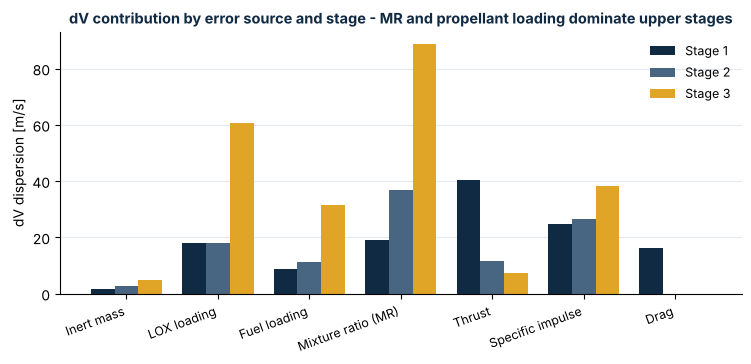

In [26]:
ex3_1_error_budget()

## 3.3 속도오차 몇 m/s가 만드는 결과

- 궤도역학은 작은 오차에 관대하지 않음

### ① 궤도 진입 실패의 문턱
- 근지점이 해수면까지 내려가는 데 필요한 속도 부족분(deorbit 조건)
  - 200 km 원궤도: 약 **60 m/s**
  - 700 km 원궤도: 약 **198 m/s**
- 60 m/s = 총 속도증분의 **0.6%에 불과**

### ② 궤도 형상 오차

$$da = \frac{2a^2}{\mu}\,V\,dV, \qquad \Delta h \approx \frac{4a^2}{\mu}\,V_p\,\Delta V_p$$

- $\pm 3$ m/s = 총 속도증분 9,300 m/s의 **0.03%**
- 그 0.03%가 고도 10 km의 궤도 오차로 증폭

| | 크기 | 총 ΔV 대비 | 의미 |
|---|---|---|---|
| 성능 산포 (3σ RSS) | ≈ 141 m/s | 1.5 % | 유도 부재 시 그대로 궤도오차로 전환 |
| 궤도 진입 실패 문턱 | ≈ 60 m/s | 0.6 % | **산포보다 작음** — 개루프만으로는 실패 가능 |
| 요구 투입 정확도 | ≈ 3 m/s | 0.03 % | 폐루프 유도 없이는 도달 불가 |

== Orbital-mechanics consequences of velocity error ==
 Circular alt [km]  Circular speed [m/s]  Failure threshold dV [m/s]  Share of total dV [%]  da @ 3 m/s [km]  dh_apogee @ 3 m/s [km]
               200               7784.26                       60.31                   0.65             5.07                   10.14
               300               7725.76                       89.27                   0.96             5.19                   10.37
               500               7612.61                      144.95                   1.56             5.42                   10.84
               700               7504.29                      197.79                   2.13             5.66                   11.32


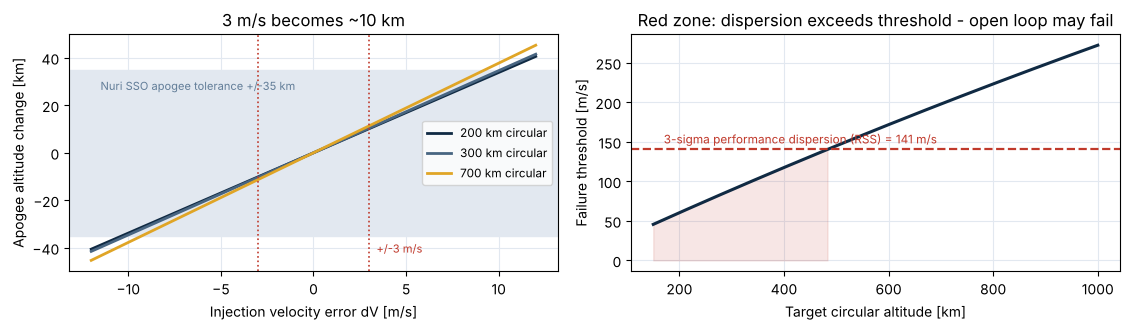

-> Below about 487 km, the 3-sigma performance dispersion (141 m/s) exceeds the failure threshold.
   For low orbits, closed-loop guidance is therefore essential.


In [27]:
ex3_2_deorbit()

## 3.4 개루프 유도와 폐루프 유도

| | 개루프 유도 (Open-Loop) | 폐루프 유도 (Closed-Loop) |
|---|---|---|
| 동작 | 자세 명령을 비행 전 설계, **시간의 함수**로 탑재 | 항법의 현재 위치·속도를 되먹임, 자세 명령·엔진 정지 시각을 **실시간 재계산** |
| 설계 목표 | 고동압 구간 받음각 최소화 | 종말 조건(목표 궤도) 만족 + 추진제 소모 최소화 |
| 산포 흡수 | 불가 | **가능 (유일한 수단)** |
| 장점 | 예측 가능, 하중 관리에 유리 | 성능 산포·외란에 강건 |

### 폐루프 유도의 두 갈래

| 구분 | 동작 방식 | 특징 | 대표 기법 |
|---|---|---|---|
| **음함수 (Implicit)** | 미리 정한 **기준궤적**으로 복귀하도록 오차 감소 | 기준궤적 이탈분만 수정 — 최적성 미보장 | Delta Guidance, Q-Guidance |
| **양함수 (Explicit)** | 현재 상태에서 목표까지 **새로운 경로**를 매 주기 재생성 | 기준궤적 불필요, 큰 이탈에도 대응 — 연산 부담 큼 | IGM, PEG, LTG, 최적유도 |

> - 실제 발사체 = 두 방식을 **시간축에서 분리**하여 사용
> - 대기권 구간: 개루프 (하중경감 포함) / 진공 구간: 양함수 폐루프
> - 현재의 표준 구성

## 3.5 대기권 구간의 지배 변수: 바람

- 쟁점: 이 구간만 '최적 궤적'을 포기하는 이유

$$F_N = \tfrac{1}{2}\rho V^2 S C_{N\alpha}\,\alpha \;\propto\; Q\,\alpha,
\qquad \text{굽힘모멘트} \;\propto\; Q\alpha \;\text{및 TVC 편향각}\ \delta$$

- 기체 대기속도 = 지구기준 속도 − **바람벡터** → **바람이 곧 받음각을 생성**
- 동압 $Q$ 최대 고도(약 10~13 km)에서 제트기류 조우 시 $Q\alpha$ 급증
- → 구조 굽힘하중과 TVC 요구 편향각이 동시에 상승

| 기법 | 내용 |
|---|---|
| **하중경감 유도 (Load-Relief)** | 자세각 대신 **받음각(또는 횡가속도)** 감소 방향으로 명령 수정. 궤적 최적성 일부 포기, 구조 여유 확보 |
| **계절풍 바이어스 (Wind Biasing)** | 계절별 평균 바람 프로파일을 피치 프로그램에 사전 반영. 99% $Q\alpha$ 게이지 기준 **15~19% 저감**, TVC 최대 요구각 **9% 저감** 보고 |
| **발사 당일 바람 운용 (Day-of-Launch)** | 발사 수 시간 전 기구(balloon) 실측 바람으로 자세 프로파일 재설계·탑재. $Q\alpha$ 기준 **50% 이상 저감** 가능 |

> **운용상의 함의**
> - 발사 당일 바람 반영 = 성능상 효과 최대
> - 절차: 발사 6시간 전부터 기구 상승 → 데이터 평가 → 궤적 재설계 → 하중 검증 → 성능 검증, 발사 1시간 이내 탑재값(I-load) 재장입
> - → **알고리즘이 아닌 발사 운용 조직·절차의 문제**
> - **발사장 운영 역량이 탑재중량으로 환산되는 대표 사례**

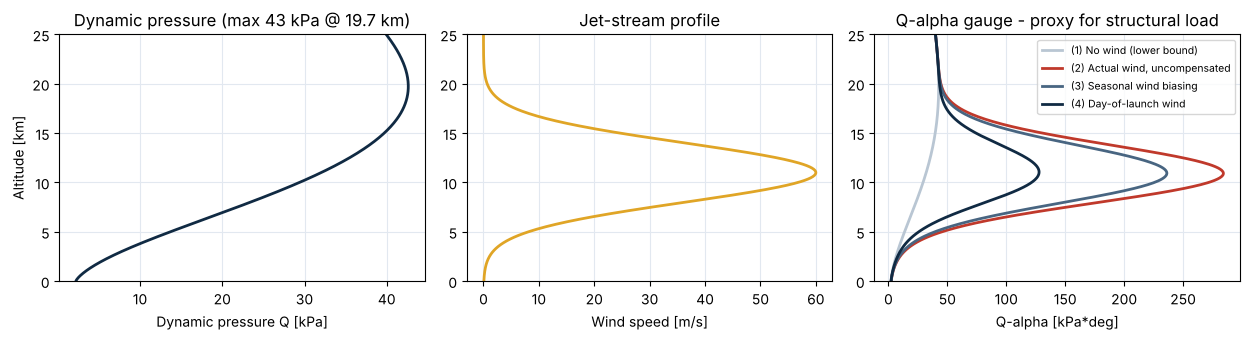

== Peak Q-alpha and reduction relative to (2) uncompensated ==
  (1) No wind (lower bound)        max Q-alpha =    42.6 kPa*deg   ( 85.0% reduction)  <- unattainable lower bound
  (2) Actual wind, uncompensated   max Q-alpha =   284.2 kPa*deg   (  0.0% reduction)
  (3) Seasonal wind biasing        max Q-alpha =   236.3 kPa*deg   ( 16.9% reduction)
  (4) Day-of-launch wind           max Q-alpha =   127.8 kPa*deg   ( 55.0% reduction)

-> Seasonal biasing ~17% and day-of-launch ~55%: the same order as reported in the literature
   (seasonal 15-19%, day-of-launch 50%+).
   Q-alpha reduction is structural margin, and structural margin converts into payload mass at design time.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: jet_ms


In [28]:
widget_qalpha()

## 3.6 최적 조향법칙은 어디에서 오는가

- 평면지구 궤도투입 문제에서 유도되는 **이중선형 탄젠트(bilinear tangent)** 법칙

### ① 문제 설정
$$\min J = t_f \quad (\text{연소시간 최소} = \text{추진제 최소})$$
$$\dot{x}=v_x,\quad \dot{y}=v_y,\quad \dot{v}_x=\frac{F}{m}\cos\alpha,\quad \dot{v}_y=\frac{F}{m}\sin\alpha - g$$
$$\text{종말조건:}\quad y_f=h_c,\quad v_{xf}=v_c,\quad v_{yf}=0$$

### ② 최적성 조건
해밀토니안 $H = L + \boldsymbol{\lambda}^T \mathbf{f}$ 에 오일러–라그랑주 식 적용
$$\dot\lambda_1=\dot\lambda_2=0,\quad \dot\lambda_3=-\lambda_1,\quad \dot\lambda_4=-\lambda_2
\;\Rightarrow\; \lambda_3 = -c_1 t + c_3,\quad \lambda_4 = -c_2 t + c_4$$
그리고 $\partial H/\partial\alpha = 0$ 으로부터

### ③ 결과
$$\boxed{\ \tan\alpha = \frac{\lambda_4}{\lambda_3} = \frac{-c_2 t + c_4}{-c_1 t + c_3}\ }$$

- 최적 자세 명령의 **탄젠트 = 시간의 일차분수함수**
- = **이중선형 탄젠트 조향법칙**

### 두 번의 단순화 — 실제 알고리즘의 출처

**① 비행거리(down-range) 비구속**
- 횡방향 종말조건 없음 → $\lambda_1 = c_1 = 0$

$$\tan\alpha = a\,t + b \qquad (\textbf{선형 탄젠트 조향법칙})$$

- 궤도투입 문제는 대개 이 경우에 해당

**② 종말 속도벡터만 구속**
- $\tan\alpha = c_4/c_3 = \text{일정}$ → **추력 방향 고정**이 최적
- 상단 유도에서 자세 명령이 거의 선형으로 완만하게 변하는 이유
- IGM이 자세를 '초기값 + 일정 변화율'로 파라미터화할 수 있는 근거

> **교훈**
> - 실제 발사체: 매 주기 최적제어 문제를 풀지 않음
> - **최적해의 함수 형태를 사전에 파악 → 계수만 실시간으로 조정**
> - '온보드 최적화 없이 최적성을 얻는 법' = 발사체 유도 알고리즘 설계의 핵심 발상

== Three steering-law FORMS meeting the same terminal conditions ==
                                   Steering-law form  Burn time t_f [s]  Propellant [kg]  Terminal residual [max]  Extra vs optimal [kg]
        Linear tangent  (tan a = A t + B)  [optimal]            206.134        94232.621                      0.0                  0.000
Linear sine  (sin a = A t + B)  [Atlas-Centaur, H-I]            207.381        94802.613                      0.0                569.992
                         Linear angle  (a = A + B t)            208.455        95293.554                      0.0               1060.933

-> The form that uses the least propellant is 'Linear tangent' - as optimal-control theory predicts.
-> Linear sine costs 570 kg more; linear angle costs 1,061 kg more.
   1,000 kg of upper-stage propellant is several hundred kg of LEO payload: the choice of form IS performance.

[How to read] In the middle panel only the optimal law gives a smooth monotonic decrease.
  Linear sin

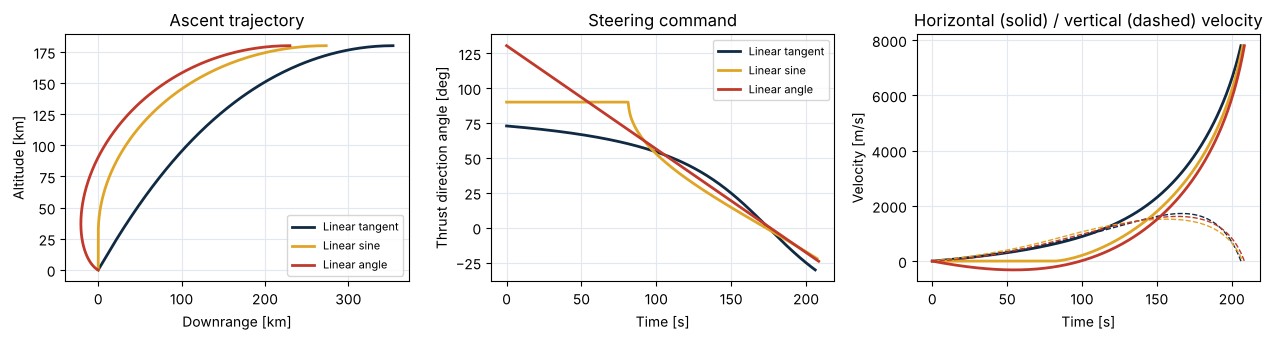


[Interactive] Run this cell in Colab/Jupyter to get sliders for: hc_km


In [29]:
widget_steering()

## 3.7 실제 발사체의 명시적 폐루프 유도 방식

- 차이의 본질 = 같은 최적해를 **어떤 형태로 파라미터화했는가**

| 유도 방식 | 채택 발사체 | 파라미터화의 특징 | 장·단점 |
|---|---|---|---|
| 선형 사인 법칙 (Linear-Sine) | Atlas-Centaur, H-I, H-II | $\sin\theta$를 시간 일차식 + 중력·속도항의 조합으로 표현 | 해석적 형태 단순, 초기 발사체에 적합 / 정확도 한계 |
| **반복 유도 방식 (IGM)** | **Saturn I·V, 누리호(KSLV-II), CZ-8** | 최적 자세명령이 거의 선형이라는 성질 활용, $\theta$를 **(초기값, 변화율)** 로 파라미터화 | 반복 계산 불필요, 연산 부담 작음 / 강한 비선형 상황에서 근사 오차 |
| 동력 명시 유도 (PEG) | Space Shuttle, SLS | IGM 보완, 자세를 스칼라 각이 아닌 **벡터 명령**으로 파라미터화 | 해가 일반적 / 예측–수정(predictor–corrector) 반복 필요 |
| 선형 탄젠트 변형 (LTG) | H-IIA, Ariane-5 | 최적해에 더 근접한 형태로 파라미터화, 또는 경계조건 연립식 선형화 후 차분보정 | 최적성 높음 / 수렴성 관리·검증 부담 큼 |

> **누리호의 IGM 계열 채택 = 보수적이면서 합리적인 선택**
> - 반복 계산 없음 → 최악의 경우에도 **연산시간이 결정론적으로 보장**
> - → 비행소프트웨어 검증(V&V) 부담 대폭 경감
> - **유도 알고리즘 선택 = 성능뿐 아니라 '검증 가능성'의 문제**

## 3.8 폐루프 명시 유도 알고리즘의 계산 순서

### 다섯 개의 목표 변수, 다섯 개의 유도 변수

**목표 변수 (5개)**
- 위치·속도 벡터는 6개이나, 궤도투입에서는 비행거리(도달 지점)가 자유변수 → 실제 구속은 5개
- 고도(반경) · 총속도 · 비행경로각(또는 수직속도) · 궤도경사각 · 승교점 적경

**결정할 유도 변수 (5개)**
- 피치 자세와 그 변화율 (2)
- 요 자세와 그 변화율 (2)
- 궤도투입까지 남은 시간 $t_{go}$ (1)

> 미지수와 구속조건의 개수 일치 = 알고리즘 성립의 **구조적 조건**

| 단계 | 내용 | 수식 |
|---|---|---|
| **①** | 속도 조건을 만족하는 자세각 $\theta_{Gv}$ 산출 | 목표 속도벡터 − 현재 속도 − 중력 기여 = 소요 속도증분 $\Delta V_G$의 방향각: $\theta_{Gv} = \tan^{-1}(\Delta V_{Gy}/\Delta V_{Gx})$ |
| **②** | 남은 연소시간 $t_{go}$ 산출 | $\tau = V_{ex}/a_0$ 갱신 후 로켓방정식의 역함수 적용: $t_{go} = \tau\left(1 - e^{-\Delta V/V_{ex}}\right)$ |
| **③** | 위치 조건까지 만족하는 $\theta_{Gp}$와 변화율 산출 | 자세를 (초기 편차 + 일정 변화율)로 설정, 적분항 $L, J, S, Q$ 로 속도·위치 종말조건을 동시에 만족하는 두 계수를 연립으로 해결 |

> - 산출 명령을 최적제어 직접 해와 비교 시, 궤도요소 기준 차이는 사실상 무시 가능
>   (예: 고도 0.2 km, 속도 0.02 m/s, 경사각 0.000°)
> - **실시간으로 풀 수 없는 문제를 실시간으로 푸는 방법 = 근사의 승리**

In [30]:
ex3_5_igm_tgo()

Stage-3 assumption: Isp = 325 s -> Vex = 3,187 m/s,  current acceleration a0 = 8.5 m/s2
                    acceleration time constant tau = Vex/a0 = 375.0 s

== t_go and integral terms vs required velocity gain ==
 Required dV [m/s]  t_go [s]  L [m/s]  J [km]  S [km]  Q [1e6 m*s]
               500     54.44    500.0   13.97   13.25         0.51
              1000    100.98   1000.0   53.13   47.85         3.67
              1500    140.76   1500.0  113.82   97.32        11.10
              2000    174.76   2000.0  192.92  156.60        23.67
              2500    203.83   2500.0  287.76  221.82        41.69

Check: L must equal the required dV -> True

== With a thrust dispersion: open loop vs closed loop ==
  thrust  -2.4% | open loop: cutoff  174.8 s fixed -> dV  1933.9 m/s (error  -66.1) | closed loop: dV 2000 m/s -> cutoff  179.1 s ( +4.3 s)
  thrust  +0.0% | open loop: cutoff  174.8 s fixed -> dV  2000.0 m/s (error   +0.0) | closed loop: dV 2000 m/s -> cutoff  174.8 s ( +0.0 s)


---
# 제4부 · 시스템 사례

> Saturn V와 Space Shuttle에서 누리호까지 — 설계 선택과 비행 결과

## 4.1 짐벌 플랫폼 시대: Saturn V와 Space Shuttle

### Saturn V
- 벤딕스社 **ST-124-M 3축 짐벌 안정 플랫폼**, 무게 51 kg
- 플랫폼 온도 43 °C 안정화 → 센서 특성 고정
- 관성좌표계 → 기체좌표 변환: **피치→요→롤** 순서의 오일러각 사용
- 요각 ±90°에서 **짐벌락** 발생 → 중간 짐벌 ±45° 제한
- 방위각: **광학 세오돌라이트**로 정렬
- 유도: **IGM(반복 유도 방식)** — 현재 누리호까지 이어지는 계보


<table><tr><td align="center" valign="top" width="300"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/NASM_ST-124.jpg?width=600" width="300" alt="ST-124 실물 (미국 국립항공우주박물관 소장)"><br><sub>ST-124 실물 (미국 국립항공우주박물관 소장)<br><a href="https://commons.wikimedia.org/wiki/File:NASM_ST-124.jpg">Wikimedia Commons</a></sub></td><td align="center" valign="top" width="300"><img src="https://commons.wikimedia.org/wiki/Special:FilePath/Apollo_Saturn_V_Instrument_Unit_Gyro_Huntsville_AL_Space_museum_ST-124.jpg?width=600" width="300" alt="Saturn V 계기장치(IU) 내 ST-124 (헌츠빌 우주센터 전시)"><br><sub>Saturn V 계기장치(IU) 내 ST-124 (헌츠빌 우주센터 전시)<br><a href="https://commons.wikimedia.org/wiki/File:Apollo_Saturn_V_Instrument_Unit_Gyro_Huntsville_AL_Space_museum_ST-124.jpg">Wikimedia Commons</a></sub></td></tr></table>

<sub>※ 사진은 온라인 상태에서 Wikimedia Commons로부터 직접 표시됨 · 저작자·라이선스는 각 링크의 파일 페이지 기준</sub>

### Space Shuttle
- 싱어-키어폿社 KT-70, **4축 짐벌** — 짐벌락 제약을 구조로 해결
- 고정밀 관성항법장치(HAINS) **3중 이중화**, 1대당 27 kg
- IMU 고장검출·분리(FDI) 논리로 **다수결** 선정
- 유도: **PEG** — 자세를 벡터 명령으로 파라미터화, 예측–수정 반복
- **발사 당일 바람 운용(Day-of-Launch)** 절차 정립

> **두 사례의 교훈**
> - Saturn V: 짐벌락(기하학적 제약)을 **운용 제한**으로 우회
> - Shuttle: 축 추가, **하드웨어**로 해결
> - 스트랩다운 + 쿼터니언: 제약 자체를 **소프트웨어**로 소멸
> - 동일 문제를 세대별로 다른 층위(운용 → 하드웨어 → 소프트웨어)에서 해결 = 시스템 공학의 전형적 궤적

## 4.2 누리호(KSLV-II)의 항법유도 시스템

- 임무 요구 → 성능 규격 → 단별 설계로 이어지는 경로 추적

In [31]:
ex4_1_nuri_specs()

== (1) Mission requirements ==
            Item              SSO              LEO
    Payload mass         1,500 kg         2,600 kg
Perigee altitude     700 +/- 7 km     300 +/- 3 km
 Apogee altitude    700 +/- 35 km    300 +/- 20 km
     Inclination 98.2 +/- 0.1 deg 80.3 +/- 0.1 deg

== (2) Inertial Navigation & Guidance Unit (INGU) performance spec ==
                 Item Spec (3 sigma)              Note
  Alignment - azimuth      0.025 deg optical alignment
    Alignment - level      0.014 deg                 -
Navigation - attitude        0.1 deg        over 900 s
Navigation - velocity        3.0 m/s        over 900 s
Navigation - position         1.5 km        over 900 s

== (3) Guidance and control by stage ==
    Stage / phase         Engine cutoff                          Guidance                      Attitude control
          Stage 1  propellant depletion Load-relief w/ day-of-launch wind                  4-engine TVC, 3 axes
          Stage 2  propellant depletion         

## 4.3 비행 전에 무엇으로 확신을 얻는가

- 누리호 항법유도장치의 **검증 체계** — 성능시험 · 환경시험 · 실환경 시험

| 단계 | 내용 |
|---|---|
| **정렬·정지항법 시험** | X·Y·Z축 각각 ±1 g가 되는 6개 자세에서 정렬오차, 자이로·가속도계 바이어스 추정치, 정지 상태 항법오차 성장을 반복 확인 |
| **환경 인증시험** | 진동(20 g rms) · 파이로 충격(SRS 3,000 g) · 고가속 · 열주기(−34 ~ +71 °C) · 열진공(1.33×10⁻² Pa) · EMC(MIL-STD-461F) <br>관성센서는 환경에 특히 민감 → **환경시험이 곧 성능시험** |
| **지상 주행 시험** | 기준 항법장치(SIGMA30) 동반 탑재, 차량 주행, 1,000초 기준 항법오차 비교 <br>자세 0.01° 이내, 속도 0.3 m/s 이내, 위치 0.12 km 이내 — 규격 대비 여유 확인 |
| **항공기 비행시험** | Cessna 208B 탑재, 2,400초 비행 <br>실제 기동·진동 환경에서 자세 0.06° 이내, 속도 0.4 m/s 이내, 위치 0.52 km 이내 확인 |

> - 검증의 계단: **정지 → 주행 → 비행 → 발사**
> - 단계마다 실환경 요소를 하나씩 추가
> - **참값을 알 수 있는 기준장치와의 비교 가능성**은 끝까지 유지
> - = 항법 검증의 기본 설계

## 4.4 누리호 2차 비행시험 결과 (2022. 6. 21)

- 항법 · 유도 · 잔류추력 — 오차를 **세 갈래로 분해**하여 해석

== (1) Navigation performance over 900 s, vs GNSS ==
                  Item  Result Unit  Spec (3 sigma)  Spec used [%]
Velocity difference dV    0.70  m/s             3.0           23.3
Altitude difference dh   -0.40   km             1.5           26.7
   Range difference dR    0.47   km             1.5           31.3
-> The inertial solution stayed within about 1/3 of spec for 900 s. Navigation met its requirement with margin.

== (2) Stage-3 engine cutoff state (time from T3) ==
                   Item  Nominal design  Guidance result  Difference
        Cutoff time [s]        526.4800         509.1300    -17.3500
          Radius R [km]       7078.1370        7078.1050     -0.0320
          Speed V [m/s]       7497.8370        7497.6910     -0.1460
Flight-path angle [deg]          0.0090           0.0256      0.0166
  RAAN difference [deg]          1.5436           1.5492      0.0056
      Inclination [deg]         98.1700          98.1470     -0.0230

== (3) Achieved orbit at sate

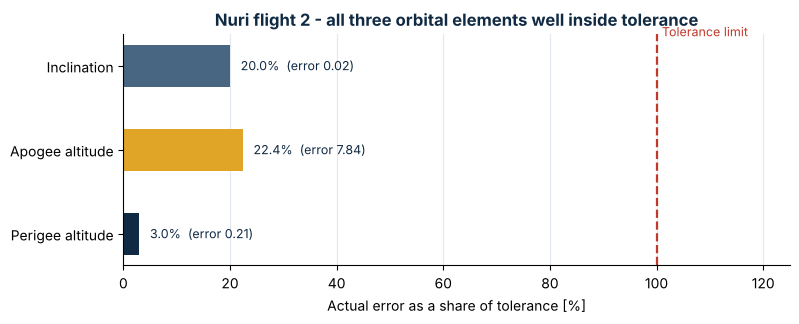

In [32]:
ex4_2_nuri_flight2()

---
## 4.5 정책 토론 · 로켓 이론 연계 과제

### Q1. GNC는 왜 '가장 늦게 국산화되는' 구성품인가
- 엔진과 달리 GNC는
  - **시험으로 성능 증명이 어려움** (참값을 알 수 없음)
  - **수출통제의 정면**에 위치
  - **실패 원인 규명이 어려움**
- 쟁점: 위 세 특성이 후발국의 개발 경로에 어떤 순서를 강요하는가

### Q2. 저비용화는 GNC에서 어디까지 가능한가
- 현황: MEMS·진동식 자이로 + GNSS 결합으로 전술급 센서만으로 궤도투입 가능해지는 추세
- 쟁점: 소형 발사체 정책의 투자 방향
  - 고성능 관성센서 국산화 지속 투자
  - 결합항법 알고리즘 역량 집중

### Q3. 발사 운용 역량은 탑재중량으로 환산되는가
- 발사 당일 바람 반영 → $Q\alpha$ 50% 이상 저감 → 구조 여유를 탑재중량으로 회수 가능
- 단, **발사장 조직·절차·의사결정 체계**의 문제
- 쟁점: 이 역량의 축적·평가 방안

> **연계**
> - 오차 예산·손실항 논의 → 로켓방정식 및 단 구성 설계
> - 수출통제·국산화 논의 → 후반부 정책 분석, 팀별 **사업기획보고서**의 기술개발 전략·위험관리 절

---
## 실습 과제

- 아래 셀 실행 → 슬라이더로 파라미터 변경 → 직접 답안 작성

In [33]:
widget_assignments()

[Assignment 1] Single-source assumption <~ 0.0584 deg/h -> with 5-source RSS allocation <~ 0.0261 deg/h  =>  Navigation grade
        -> Is this grade MTCR-controlled? Is a domestic substitute available? Discuss in your report.

[Interactive] Run this cell in Colab/Jupyter to get sliders for: T_coast, dV_spec, N_SRC
[Assignment 2] dV reserve needed by an open-loop design ~ 67.5 m/s
               On a 1,500 kg payload that is about 32.1 kg of extra propellant  <- what closed-loop guidance gives back

[Interactive] Run this cell in Colab/Jupyter to get sliders for: disp_pct, m_pl

[Assignment 3] Use the slider of widget_steering() (section 3.6) at 120, 180 and 250 km and compare how the
               propellant penalty of linear-sine vs linear-tangent guidance changes.


---
## 참고문헌 및 유의사항

1. 노웅래, 「Space Launch Vehicle Course — 8th lecture: Navigation and Guidance System」, 한국항공우주연구원 발사체연구소, 2024. 4. 30.
2. B. N. Suresh, K. Sivan, *Integrated Design for Space Transportation System*, Springer, 2015.
3. D. H. Titterton, J. L. Weston, *Strapdown Inertial Navigation Technology*, 2nd ed., AIAA, 2004.
4. R. M. Rogers, *Applied Mathematics in Integrated Navigation Systems*, 3rd ed., AIAA, 2007.
5. J. M. Longuski, J. J. Guzmán, J. E. Prussing, *Optimal Control with Aerospace Applications*, Springer, 2014.
6. G. W. Cherry, "A Unified Explicit Technique for Performing Orbital Insertion, Soft Landing, and Rendezvous," AIAA-63-335, 1963.
7. W. Haeussermann, "Description and Performance of the Saturn Launch Vehicle's Navigation, Guidance, and Control System," NASA TN D-5869, 1970.
8. R. L. McHenry, T. J. Brand, A. D. Long, "Space Shuttle Ascent Guidance, Navigation, and Control," *J. of the Astronautical Sciences*, Vol. 27, No. 1, 1979.
9. B. E. Harrington, "Space Shuttle Day-of-Launch Trajectory Design Operations," AIAA Space 2011 Conference.
10. S. Nishihira et al., "An Overview of the Guidance and Control System for H-IIA Launch Vehicle," 50th IAC, 1999.
11. 노웅래 외, 「한국형발사체 2차 비행시험에서의 관성항법유도장치의 비행 결과」, 한국항공우주학회 2022 추계학술대회.
12. 노웅래 외, 「한국형발사체 관성항법유도장치의 3단 폐루프 유도 결과」, 한국항공우주학회 2022 추계학술대회.

> **유의사항**
> - 본 자료 = 위 공개 문헌의 데이터·논지를 **강의 목적에 맞게 재구성·재서술한 요약·해설** (원문의 문장·도표를 그대로 옮기지 않음)
> - 본 노트북의 수치 실습 = 개념의 차수(order) 체득용 **교육용 단순 모델**, 실제 설계값 아님
> - 정확한 수치·전거·각주 필요 시(특히 보고서·논문 작성) 원전을 직접 확인하여 1차 출처로 인용

### 사진·제품 참고 링크
- 사진: Wikimedia Commons 공개 파일 (각 그림 아래 링크의 파일 페이지에 저작자·라이선스 명시)
  - 수업 배포 시 각 파일 페이지의 라이선스 표기 조건(저작자 표시 등) 확인 권장
- 제조사 제품 페이지 (사진·규격 참고용)
  - Honeywell GG1320AN 디지털 RLG: https://aerospace.honeywell.com/us/en/products-and-services/product/hardware-and-systems/sensors/gg1320an-digital-ring-laser-gyroscope
  - Honeywell Q-Flex QA-2000 석영 가속도계: https://aerospace.honeywell.com/us/en/products-and-services/product/hardware-and-systems/sensors/qa-2000-single-axis-quartz-accelerometer
  - Northrop Grumman LN-200 FOG IMU: https://northropgrumman.com/what-we-do/air/ln-200-fog-family-advanced-airborne-imu-ahrs
  - Exail 발사체용 INS: https://www.exail.com/product-range/ins-for-launch-vehicles
  - Safran HRG Crystal: https://www.safran-group.com/news/safrans-hrg-crystaltm-and-onyxtm-revolution-high-performance-naval-inertial-reference-systems-2018-10-23
- 추가 참고문헌
  - D. H. Titterton, J. L. Weston (위 3번) — RLG 록인·디더, FOG 위상변조, 코닝/스컬링 알고리즘
  - P. D. Groves, *Principles of GNSS, Inertial, and Multisensor Integrated Navigation Systems*, 2nd ed., Artech House, 2013 — 슐러 진동, 수직 채널, 결합항법
  - G. H. Bryan, "On the beats in the vibrations of a revolving cylinder or bell," *Proc. Cambridge Phil. Soc.*, 1890 — HRG의 원리